# Notebook 05 — Transformer baselines (Local + Centralized + Federated)

**Purpose.** This notebook evaluates the Transformer as the third deep-learning architecture after Notebook 03 (GRU) and Notebook 04 (LSTM). The aim is not to create a separate final comparison notebook here. The aim is to answer one controlled question: does replacing recurrent models with an attention-based Transformer change the conclusions observed with GRU and LSTM?

The experimental setting is kept consistent with the previous notebooks: same preprocessed tensors, same active clients, same chronological splits, same class labels, same evaluation protocol, and the same local, centralized, FedAvg, and FedProx structure. The main difference is the model body: a Transformer encoder replaces the recurrent unit.

**Reporting structure.** The notebook first evaluates Transformer baselines in the local, centralized, and federated settings. It then adds two Transformer-specific checks: a capacity ablation and a design ablation. Finally, a short deep-learning architecture synthesis compares GRU, LSTM, and Transformer. The full thesis-level comparison with classical machine-learning models is left to Notebook 09.

**Inputs.**
- Preprocessed sequence tensors from Notebook 02.
- GRU baseline reference values from Notebook 03.
- LSTM baseline reference values from Notebook 04.

**Outputs.** The notebook saves Transformer models, predictions, training histories, per-client test metrics, per-class reports, modal-density-stratified results, capacity/design ablation tables, deep-learning architecture comparison tables, and a manifest for later notebooks.


## Section 0 — Setup


In [47]:
# 0.1 — Imports
import os, json, time, random, copy, math, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
)

warnings.filterwarnings("ignore", message="y_pred contains classes not in y_true")

print("Imports ready.")

Imports ready.


In [48]:
# 0.2 — Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"Device: {device}")
if torch.cuda.is_available():
    print(f"GPU   : {torch.cuda.get_device_name(0)}")

Device: cuda
GPU   : Tesla T4


In [49]:
# 0.3 — Paths
# Auto-discover Notebook 02 outputs
n02_candidates = []
for root, dirs, files in os.walk("/kaggle/input"):
    if "preprocess_manifest.json" in files:
        n02_candidates.append(Path(root))
assert n02_candidates, (
    "No preprocess_manifest.json found under /kaggle/input. "
    "Attach Notebook 02 outputs as a Kaggle dataset."
)
PREPROCESS_DIR = n02_candidates[0]
TENSOR_DIR     = PREPROCESS_DIR / "tensors"
MANIFEST_PATH  = PREPROCESS_DIR / "preprocess_manifest.json"

# Auto-discover Notebook 03 (GRU) outputs — has the GRU all-variants file
#   and the GRU-named local summary (no 'lstm' in the name).
gru_candidates = []
for root, dirs, files in os.walk("/kaggle/input"):
    if ("federated_all_variants_test_results.csv" in files
            and "local_test_summary.csv" in files):
        gru_candidates.append(Path(root))
assert gru_candidates, (
    "Notebook 03 (GRU) outputs not found. Attach the dataset containing "
    "'federated_all_variants_test_results.csv' and 'local_test_summary.csv'."
)
GRU_AUDIT_DIR = gru_candidates[0]

# Auto-discover Notebook 04 (LSTM) outputs — has the LSTM all-variants file.
lstm_candidates = []
for root, dirs, files in os.walk("/kaggle/input"):
    if "federated_lstm_all_variants_test_results.csv" in files:
        lstm_candidates.append(Path(root))
assert lstm_candidates, (
    "Notebook 04 (LSTM) outputs not found. Attach the dataset containing "
    "'federated_lstm_all_variants_test_results.csv'."
)
LSTM_AUDIT_DIR = lstm_candidates[0]

OUTPUT_DIR = Path("/kaggle/working/transformer_baselines")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
(MODELS_DIR := OUTPUT_DIR / "models").mkdir(exist_ok=True)
(AUDIT_DIR  := OUTPUT_DIR / "audit").mkdir(exist_ok=True)
(PREDS_DIR  := OUTPUT_DIR / "predictions").mkdir(exist_ok=True)

print(f"Notebook 02 dir : {PREPROCESS_DIR}")
print(f"Notebook 03 dir : {GRU_AUDIT_DIR}")
print(f"Notebook 04 dir : {LSTM_AUDIT_DIR}")
print(f"Output dir      : {OUTPUT_DIR}")

Notebook 02 dir : /kaggle/input/datasets/sarahaddouda/preprocess-outputs
Notebook 03 dir : /kaggle/input/datasets/sarahaddouda/gru-baselines/audit
Notebook 04 dir : /kaggle/input/datasets/sarahaddouda/lstm-baselines/audit
Output dir      : /kaggle/working/transformer_baselines


In [50]:
# 0.4 — Constants (frozen — must match Notebooks 02, 03, 04)
ACTIVE_CLIENTS = ["England", "Ireland", "USA"]
FEATURE_COLS   = ["NH3", "BOD", "DO", "PO4", "pH", "Temp", "Nitrogen", "Nitrate"]
SPLITS         = ["train", "val", "test"]

WINDOW    = 12
N_FEATS   = len(FEATURE_COLS)
N_CLASSES = 5

CCME_CLASS_ORDER = ["Excellent", "Good", "Fair", "Marginal", "Poor"]
INT_TO_CLASS = {i: c for i, c in enumerate(CCME_CLASS_ORDER)}
CLASS_NAMES  = CCME_CLASS_ORDER

print(f"Active clients : {ACTIVE_CLIENTS}")
print(f"Features ({N_FEATS}): {FEATURE_COLS}")
print(f"Classes ({N_CLASSES}) : {CLASS_NAMES}")

Active clients : ['England', 'Ireland', 'USA']
Features (8): ['NH3', 'BOD', 'DO', 'PO4', 'pH', 'Temp', 'Nitrogen', 'Nitrate']
Classes (5) : ['Excellent', 'Good', 'Fair', 'Marginal', 'Poor']


## Section 1 — Load tensors and prior-architecture baselines

This section loads the model-ready tensors produced by Notebook 02 and the reference results from Notebooks 03 and 04. These GRU and LSTM results are used only for the final deep-learning architecture synthesis in Section 14. They are loaded from saved CSV files instead of being hardcoded, so the comparison remains connected to the executed outputs.


In [93]:
# 1.1 — Load preprocessing manifest and tensors
with open(MANIFEST_PATH, "r", encoding="utf-8") as f:
    preprocess_manifest = json.load(f)

data = {}
for client in ACTIVE_CLIENTS:
    npz_path = TENSOR_DIR / f"{client.lower()}_stage1_sequences.npz"
    assert npz_path.exists(), f"Missing tensor file: {npz_path}"
    archive = np.load(npz_path)
    data[client] = {}
    for split in SPLITS:
        data[client][split] = {
            "X":            archive[f"X_{split}"],
            "y":            archive[f"y_{split}"],
            "mask":         archive[f"mask_{split}"],
            "site_ids":     archive[f"site_ids_{split}"],
            "target_dates": archive[f"target_dates_{split}"],
        }
    archive.close()

print("Loaded tensors:")
for client in ACTIVE_CLIENTS:
    sizes = " | ".join(f"{s}={data[client][s]['X'].shape[0]:>6,}" for s in SPLITS)
    print(f"  [{client:<8}] {sizes}")

Loaded tensors:
  [England ] train=76,530 | val= 8,490 | test=11,942
  [Ireland ] train=27,778 | val= 4,296 | test= 5,887
  [USA     ] train=30,222 | val= 1,770 | test= 1,979


In [52]:
# 1.2 — Verify tensors against the Notebook 02 manifest
verify_rows = []
for client in ACTIVE_CLIENTS:
    expected_counts = preprocess_manifest["sequence_counts"][client]
    for split in SPLITS:
        X = data[client][split]["X"]; y = data[client][split]["y"]; mask = data[client][split]["mask"]
        ok = (
            X.shape == mask.shape and X.ndim == 3
            and X.shape[1:] == (WINDOW, N_FEATS)
            and y.shape == (X.shape[0],)
            and X.shape[0] == expected_counts[split]
            and np.isfinite(X).all()
            and y.min() >= 0 and y.max() < N_CLASSES
        )
        verify_rows.append({"Client": client, "Split": split, "N": X.shape[0],
                            "X_shape": str(tuple(X.shape)), "OK": "ok" if ok else "FAIL"})
verify_df = pd.DataFrame(verify_rows)
display(verify_df)
assert (verify_df["OK"] == "ok").all(), "Tensor verification failed."
print("\nAll tensors verified.")

,Client,Split,N,X_shape,OK
0,England,train,76530,"(76530, 12, 8)",ok
1,England,val,8490,"(8490, 12, 8)",ok
2,England,test,11942,"(11942, 12, 8)",ok
3,Ireland,train,27778,"(27778, 12, 8)",ok
4,Ireland,val,4296,"(4296, 12, 8)",ok
5,Ireland,test,5887,"(5887, 12, 8)",ok
6,USA,train,30222,"(30222, 12, 8)",ok
7,USA,val,1770,"(1770, 12, 8)",ok
8,USA,test,1979,"(1979, 12, 8)",ok



All tensors verified.


In [53]:
# 1.3 — Load GRU (N03) and LSTM (N04) baseline reference values
gru_local_df       = pd.read_csv(GRU_AUDIT_DIR / "local_test_summary.csv")
gru_centralized_df = pd.read_csv(GRU_AUDIT_DIR / "centralized_test_summary.csv")
gru_all_fed_df     = pd.read_csv(GRU_AUDIT_DIR / "federated_all_variants_test_results.csv")

lstm_local_df       = pd.read_csv(LSTM_AUDIT_DIR / "local_lstm_test_summary.csv")
lstm_centralized_df = pd.read_csv(LSTM_AUDIT_DIR / "centralized_lstm_test_summary.csv")
lstm_all_fed_df     = pd.read_csv(LSTM_AUDIT_DIR / "federated_lstm_all_variants_test_results.csv")

for df, needed, name in [
    (gru_local_df,        ["Client","Macro_F1_present_classes"], "GRU local"),
    (gru_all_fed_df,      ["Variant","Client","Macro_F1_present_classes"], "GRU federated"),
    (lstm_local_df,       ["Client","Macro_F1_present_classes"], "LSTM local"),
    (lstm_all_fed_df,     ["Variant","Client","Macro_F1_present_classes"], "LSTM federated"),
]:
    for col in needed:
        assert col in df.columns, f"Missing '{col}' in {name} file."

print("Loaded prior-architecture baselines:")
print(f"  GRU  federated variants: {gru_all_fed_df['Variant'].nunique()}")
print(f"  LSTM federated variants: {lstm_all_fed_df['Variant'].nunique()}")

Loaded prior-architecture baselines:
  GRU  federated variants: 6
  LSTM federated variants: 6


## Section 2 — Architecture and hyperparameter rationale

The Transformer encoder replaces the recurrent unit. All other experimental factors are kept aligned with Notebooks 03 and 04 so that the comparison remains fair.

### Architecture

| Choice | Value | Reason |
|---|---|---|
| Model family | Transformer encoder | Attention-based counterpart to the GRU and LSTM. Encoder-only is appropriate because the task is sequence classification, not sequence generation. |
| Feature projection | Linear(8 → d_model) | The 8 input features are projected into the model dimension before applying attention. |
| Positional encoding | Sinusoidal positional encoding | Self-attention does not know the order of months by itself, so positional information is required. |
| Read-out | Mean pooling over the 12 months, followed by a linear classifier | Produces one sequence representation for predicting the next-month class. This is simple and stable for short 12-month sequences. |

### Transformer-specific hyperparameters

| Hyperparameter | Value | Reason |
|---|---|---|
| d_model | 64 | Matches the GRU/LSTM hidden size, keeping the main architecture comparison controlled. |
| nhead | 4 | Gives 16 dimensions per attention head. |
| num_layers | 2 | A compact encoder is more suitable for this dataset than a deep Transformer. |
| dim_feedforward | 128 | Standard feed-forward width, approximately 2× d_model. |

### Training and federated settings

The local and centralized Transformer models use the same general protocol as the recurrent baselines: Adam optimizer, learning rate 1e-3, batch size 256, early stopping on validation macro-F1, gradient clipping, and class-weighted cross-entropy.

The federated section mirrors the GRU and LSTM notebooks: three FedAvg variants and three FedProx variants are tested. This keeps the comparison controlled. Section 14 later compares the Transformer against GRU and LSTM using the saved results.

### Capacity ablation

The main Transformer uses d_model = 64 for fairness. Section 12 separately checks whether changing the model width to 32 or 128 changes the conclusion. These wider/smaller models are diagnostic only; they are not used as the main architecture comparison.


## Section 3 — Model and shared utilities

The training and evaluation infrastructure is identical to Notebooks 03 and 04.
Only the model class (Section 3.2) is Transformer-specific.


In [54]:
# 3.1 — SequenceDataset
class SequenceDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.long)
    def __len__(self):
        return len(self.y)
    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

In [55]:
# 3.2 — Transformer encoder classifier
class PositionalEncoding(nn.Module):
    """Fixed sinusoidal positional encoding added to the projected inputs."""
    def __init__(self, d_model, max_len=64):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
        div_term = torch.exp(
            torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model)
        )
        pe[:, 0::2] = torch.sin(position * div_term)
        if d_model % 2 == 0:
            pe[:, 1::2] = torch.cos(position * div_term)
        else:
            pe[:, 1::2] = torch.cos(position * div_term)[:, :pe[:, 1::2].shape[1]]
        self.register_buffer("pe", pe.unsqueeze(0))  # (1, max_len, d_model)

    def forward(self, x):
        # x: (batch, seq_len, d_model)
        return x + self.pe[:, : x.size(1)]


class TransformerClassifier(nn.Module):
    """Feature projection + positional encoding + Transformer encoder +
    mean-pool + linear classification head."""
    def __init__(self, input_size=N_FEATS, d_model=64, nhead=4,
                 num_layers=2, dim_feedforward=128,
                 num_classes=N_CLASSES, dropout=0.2):
        super().__init__()
        self.input_proj  = nn.Linear(input_size, d_model)
        self.pos_encoder = PositionalEncoding(d_model, max_len=WINDOW + 1)
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=dim_feedforward,
            dropout=dropout,
            batch_first=True,
            activation="gelu",
        )
        self.encoder     = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)
        self.dropout     = nn.Dropout(dropout)
        self.classifier  = nn.Linear(d_model, num_classes)

    def forward(self, x):
        x = self.input_proj(x)        # (batch, seq, d_model)
        x = self.pos_encoder(x)
        x = self.encoder(x)           # (batch, seq, d_model)
        x = x.mean(dim=1)             # mean-pool over time -> (batch, d_model)
        x = self.dropout(x)
        return self.classifier(x)


MODEL_CONFIG = {
    "input_size":      N_FEATS,
    "d_model":         64,
    "nhead":           4,
    "num_layers":      2,
    "dim_feedforward": 128,
    "num_classes":     N_CLASSES,
    "dropout":         0.2,
}

TRAIN_CONFIG = {
    "batch_size":               256,
    "learning_rate":            1e-3,
    "weight_decay":             1e-4,
    "max_epochs":               50,
    "early_stopping_patience":  10,
    "lr_scheduler_patience":    3,
    "lr_scheduler_factor":      0.5,
    "gradient_clip_norm":       1.0,
    "primary_metric":           "macro_f1",
    "max_class_weight":         10.0,
}

def count_trainable_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

n_params = count_trainable_parameters(TransformerClassifier(**MODEL_CONFIG))
print("TransformerClassifier defined.")
print(f"  Trainable parameters: {n_params:,}")
print(f"  Architecture: {MODEL_CONFIG}")

TransformerClassifier defined.
  Trainable parameters: 67,845
  Architecture: {'input_size': 8, 'd_model': 64, 'nhead': 4, 'num_layers': 2, 'dim_feedforward': 128, 'num_classes': 5, 'dropout': 0.2}


In [56]:
# 3.3 — Loaders and metrics
def make_loader(X, y, batch_size, shuffle):
    ds = SequenceDataset(X, y)
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle,
                      num_workers=0, pin_memory=torch.cuda.is_available())


def compute_metrics(y_true, y_pred):
    return {
        "accuracy":          accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "macro_f1":          f1_score(y_true, y_pred, labels=list(range(N_CLASSES)),
                                      average="macro", zero_division=0),
        "weighted_f1":       f1_score(y_true, y_pred, labels=list(range(N_CLASSES)),
                                      average="weighted", zero_division=0),
    }


def compute_test_metrics(y_true, y_pred):
    present_labels = sorted(np.unique(y_true).tolist())
    return {
        "accuracy":                 accuracy_score(y_true, y_pred),
        "balanced_accuracy":        balanced_accuracy_score(y_true, y_pred),
        "macro_f1_all_classes":     f1_score(y_true, y_pred, labels=list(range(N_CLASSES)),
                                             average="macro", zero_division=0),
        "macro_f1_present_classes": f1_score(y_true, y_pred, labels=present_labels,
                                             average="macro", zero_division=0),
        "weighted_f1":              f1_score(y_true, y_pred, labels=list(range(N_CLASSES)),
                                            average="weighted", zero_division=0),
        "present_classes":          ", ".join(INT_TO_CLASS[i] for i in present_labels),
    }

In [57]:
# 3.4 — Class-weight helper (with cap, consistent with N03/N04)
def inverse_frequency_weights(y, cap=TRAIN_CONFIG["max_class_weight"]):
    counts = np.bincount(y, minlength=N_CLASSES).astype(np.float64)
    N = counts.sum()
    w = np.zeros(N_CLASSES, dtype=np.float64)
    present = counts > 0
    w[present] = N / (present.sum() * counts[present])
    w[present] = w[present] / w[present].mean()
    w = np.minimum(w, cap)
    if (w > 0).any():
        w[w > 0] = w[w > 0] / w[w > 0].mean()
    return w.astype(np.float32), counts.astype(int)

In [58]:
# 3.5 — Train / eval functions
def train_one_epoch(model, loader, criterion, optimizer):
    model.train()
    total_loss = 0.0; total_samples = 0
    for X_batch, y_batch in loader:
        X_batch = X_batch.to(device); y_batch = y_batch.to(device)
        optimizer.zero_grad()
        logits = model(X_batch)
        loss = criterion(logits, y_batch)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), TRAIN_CONFIG["gradient_clip_norm"])
        optimizer.step()
        bs = X_batch.size(0)
        total_loss += loss.item() * bs; total_samples += bs
    return total_loss / total_samples


def evaluate(model, loader, criterion=None):
    model.eval()
    total_loss = 0.0; total_samples = 0
    all_true, all_pred = [], []
    with torch.no_grad():
        for X_batch, y_batch in loader:
            X_batch = X_batch.to(device); y_batch = y_batch.to(device)
            logits = model(X_batch)
            if criterion is not None:
                loss = criterion(logits, y_batch)
                total_loss += loss.item() * X_batch.size(0); total_samples += X_batch.size(0)
            preds = torch.argmax(logits, dim=1)
            all_true.append(y_batch.cpu().numpy()); all_pred.append(preds.cpu().numpy())
    y_true = np.concatenate(all_true); y_pred = np.concatenate(all_pred)
    out = compute_metrics(y_true, y_pred)
    out["loss"] = total_loss / total_samples if total_samples > 0 else float("nan")
    out["y_true"], out["y_pred"] = y_true, y_pred
    return out


def predict(model, X, batch_size=TRAIN_CONFIG["batch_size"]):
    ds = SequenceDataset(X, np.zeros(len(X), dtype=np.int64))
    loader = DataLoader(ds, batch_size=batch_size, shuffle=False)
    model.eval()
    all_pred, all_proba = [], []
    with torch.no_grad():
        for X_batch, _ in loader:
            X_batch = X_batch.to(device)
            logits = model(X_batch)
            proba = torch.softmax(logits, dim=1)
            preds = torch.argmax(logits, dim=1)
            all_pred.append(preds.cpu().numpy()); all_proba.append(proba.cpu().numpy())
    return np.concatenate(all_pred), np.concatenate(all_proba)

In [59]:
# 3.6 — Generic supervised training loop with early stopping
def train_supervised(model, train_loader, val_loader, criterion, label=""):
    optimizer = torch.optim.Adam(model.parameters(),
                                 lr=TRAIN_CONFIG["learning_rate"],
                                 weight_decay=TRAIN_CONFIG["weight_decay"])
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max",
        factor=TRAIN_CONFIG["lr_scheduler_factor"],
        patience=TRAIN_CONFIG["lr_scheduler_patience"])

    best_state, best_metric, best_epoch = None, -np.inf, 0
    epochs_without_improvement = 0
    history = []

    for epoch in range(1, TRAIN_CONFIG["max_epochs"] + 1):
        t0 = time.time()
        train_loss = train_one_epoch(model, train_loader, criterion, optimizer)
        val_metrics = evaluate(model, val_loader, criterion)
        val_macro_f1 = val_metrics["macro_f1"]
        scheduler.step(val_macro_f1)

        improved = val_macro_f1 > best_metric + 1e-6
        if improved:
            best_metric, best_epoch = val_macro_f1, epoch
            best_state = copy.deepcopy(model.state_dict())
            epochs_without_improvement = 0; marker = "*"
        else:
            epochs_without_improvement += 1; marker = ""

        history.append({
            "epoch": epoch, "train_loss": train_loss,
            "val_loss": val_metrics["loss"], "val_accuracy": val_metrics["accuracy"],
            "val_balanced_accuracy": val_metrics["balanced_accuracy"],
            "val_macro_f1": val_macro_f1, "val_weighted_f1": val_metrics["weighted_f1"],
            "learning_rate": optimizer.param_groups[0]["lr"], "time_sec": time.time() - t0,
        })
        if label:
            print(f"[{label}] ep {epoch:02d} | train_loss={train_loss:.4f} | "
                  f"val_macro_f1={val_macro_f1:.4f} | val_acc={val_metrics['accuracy']:.4f} {marker}")

        if epochs_without_improvement >= TRAIN_CONFIG["early_stopping_patience"]:
            if label:
                print(f"[{label}] early stop at epoch {epoch}. "
                      f"Best epoch = {best_epoch}, best val_macro_f1 = {best_metric:.4f}")
            break

    if best_state is not None:
        model.load_state_dict(best_state)
    return model, pd.DataFrame(history), {
        "best_epoch": best_epoch, "best_val_macro_f1": best_metric, "n_epochs_run": len(history),
    }

In [60]:
# 3.7 — Smoke test on one real batch
loader = make_loader(data["Ireland"]["train"]["X"], data["Ireland"]["train"]["y"],
                     batch_size=32, shuffle=True)
X_batch, y_batch = next(iter(loader))
m = TransformerClassifier(**MODEL_CONFIG).to(device)
logits = m(X_batch.to(device))
loss = nn.CrossEntropyLoss()(logits, y_batch.to(device))
print(f"Input shape : {tuple(X_batch.shape)}")
print(f"Logits shape: {tuple(logits.shape)}")
print(f"Loss        : {loss.item():.4f}")
del m

Input shape : (32, 12, 8)
Logits shape: (32, 5)
Loss        : 1.5355


## Section 4 — Local Transformer baselines

One Transformer trained per client on that client's data only — the
no-collaboration floor. Organised as **(4.1) train → (4.2) inspect training
behavior → (4.3) test evaluation**.


In [61]:
# 4.1 — Train a local Transformer on each client
local_models    = {}
local_histories = {}
local_summaries = {}

for client in ACTIVE_CLIENTS:
    print(f"\n=== Local Transformer: {client} (training) ===")
    weights, _ = inverse_frequency_weights(data[client]["train"]["y"])
    criterion = nn.CrossEntropyLoss(weight=torch.tensor(weights, device=device))
    train_loader = make_loader(data[client]["train"]["X"], data[client]["train"]["y"],
                               TRAIN_CONFIG["batch_size"], shuffle=True)
    val_loader = make_loader(data[client]["val"]["X"], data[client]["val"]["y"],
                             TRAIN_CONFIG["batch_size"], shuffle=False)
    model = TransformerClassifier(**MODEL_CONFIG).to(device)
    model, hist_df, summary = train_supervised(model, train_loader, val_loader,
                                               criterion, label=client[:3].upper())
    local_models[client] = model
    local_histories[client] = hist_df
    local_summaries[client] = summary

print("\nAll local Transformer models trained.")


=== Local Transformer: England (training) ===
[ENG] ep 01 | train_loss=0.7462 | val_macro_f1=0.7109 | val_acc=0.7524 *
[ENG] ep 02 | train_loss=0.6644 | val_macro_f1=0.6962 | val_acc=0.7617 
[ENG] ep 03 | train_loss=0.6487 | val_macro_f1=0.7135 | val_acc=0.7698 *
[ENG] ep 04 | train_loss=0.6413 | val_macro_f1=0.7161 | val_acc=0.7687 *
[ENG] ep 05 | train_loss=0.6370 | val_macro_f1=0.7237 | val_acc=0.7637 *
[ENG] ep 06 | train_loss=0.6369 | val_macro_f1=0.7156 | val_acc=0.7743 
[ENG] ep 07 | train_loss=0.6315 | val_macro_f1=0.7267 | val_acc=0.7726 *
[ENG] ep 08 | train_loss=0.6265 | val_macro_f1=0.7159 | val_acc=0.7602 
[ENG] ep 09 | train_loss=0.6274 | val_macro_f1=0.7309 | val_acc=0.7824 *
[ENG] ep 10 | train_loss=0.6201 | val_macro_f1=0.7271 | val_acc=0.7693 
[ENG] ep 11 | train_loss=0.6196 | val_macro_f1=0.7275 | val_acc=0.7790 
[ENG] ep 12 | train_loss=0.6196 | val_macro_f1=0.7310 | val_acc=0.7892 *
[ENG] ep 13 | train_loss=0.6185 | val_macro_f1=0.7266 | val_acc=0.7744 
[ENG] ep 1

Local Transformer training summary:


,Client,Epochs_run,Best_epoch,Init_train_loss,Final_train_loss,Init_val_loss,Best_val_loss,Best_val_macro_F1,Best_val_accuracy
0,England,47,37,0.7462,0.5812,0.5579,0.5063,0.7411,0.7841
1,Ireland,30,20,1.1258,0.6785,0.7960,0.7051,0.3275,0.8433
2,USA,19,9,1.1645,0.6038,0.5470,0.4371,0.3464,0.9593


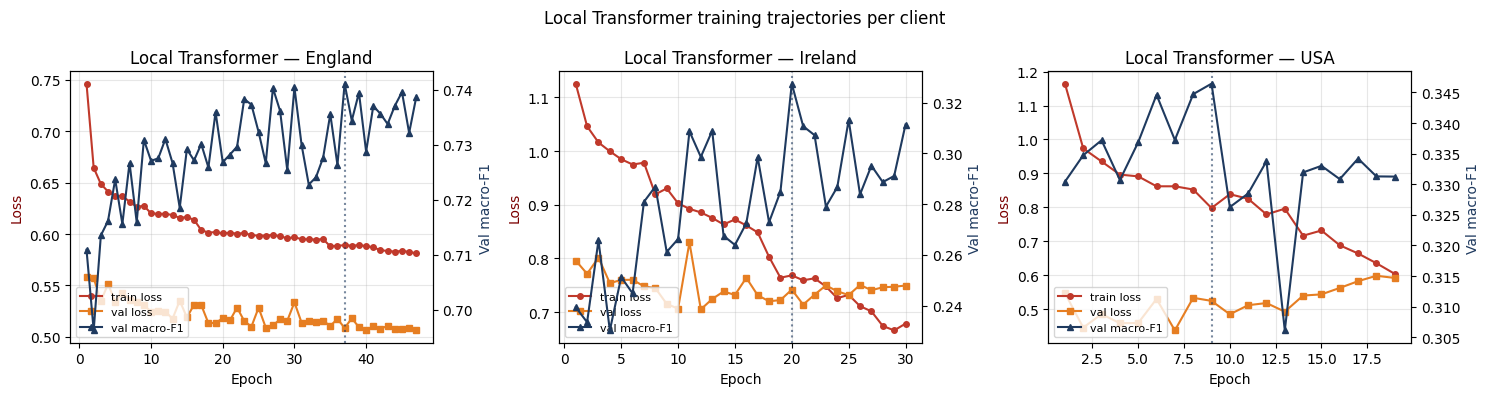

In [62]:
# 4.2 — Local training behavior: summary + curves
local_train_summary_rows = []
for client in ACTIVE_CLIENTS:
    h = local_histories[client]
    best_row = h.loc[h["val_macro_f1"].idxmax()]
    local_train_summary_rows.append({
        "Client": client, "Epochs_run": len(h), "Best_epoch": int(best_row["epoch"]),
        "Init_train_loss": round(h["train_loss"].iloc[0], 4),
        "Final_train_loss": round(h["train_loss"].iloc[-1], 4),
        "Init_val_loss": round(h["val_loss"].iloc[0], 4),
        "Best_val_loss": round(h["val_loss"].min(), 4),
        "Best_val_macro_F1": round(best_row["val_macro_f1"], 4),
        "Best_val_accuracy": round(best_row["val_accuracy"], 4),
    })
local_train_summary_df = pd.DataFrame(local_train_summary_rows)
local_train_summary_df.to_csv(AUDIT_DIR / "local_transformer_training_summary.csv", index=False)
print("Local Transformer training summary:")
display(local_train_summary_df)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, client in zip(axes, ACTIVE_CLIENTS):
    h = local_histories[client]; ax2 = ax.twinx()
    ax.plot(h["epoch"], h["train_loss"], "o-", color="#C0392B", ms=4, label="train loss")
    ax.plot(h["epoch"], h["val_loss"], "s-", color="#E67E22", ms=4, label="val loss")
    ax2.plot(h["epoch"], h["val_macro_f1"], "^-", color="#1F3A5F", ms=4, label="val macro-F1")
    be = h.loc[h["val_macro_f1"].idxmax(), "epoch"]
    ax2.axvline(be, color="#1F3A5F", ls=":", alpha=0.6)
    ax.set_xlabel("Epoch"); ax.set_ylabel("Loss", color="#7B0000")
    ax2.set_ylabel("Val macro-F1", color="#1F3A5F"); ax.set_title(f"Local Transformer — {client}")
    ax.grid(True, alpha=0.3)
    l1,la1 = ax.get_legend_handles_labels(); l2,la2 = ax2.get_legend_handles_labels()
    ax.legend(l1+l2, la1+la2, loc="lower left", fontsize=8)
plt.suptitle("Local Transformer training trajectories per client")
plt.tight_layout()
plt.savefig(AUDIT_DIR / "local_transformer_training_curves.png", dpi=120, bbox_inches="tight")
plt.show()

In [63]:
# 4.3 — Local Transformer test evaluation
local_test_metrics = {}; local_predictions = {}; local_test_rows = []; local_per_class = []
for client in ACTIVE_CLIENTS:
    print(f"Evaluating local Transformer on {client} test set")
    model = local_models[client]
    y_true = data[client]["test"]["y"]
    y_pred, y_proba = predict(model, data[client]["test"]["X"])
    m = compute_test_metrics(y_true, y_pred)
    local_test_metrics[client] = m
    local_predictions[client]  = {"y_true": y_true, "y_pred": y_pred, "y_proba": y_proba}
    local_test_rows.append({
        "Client": client, "N_test": len(y_true),
        "Best_epoch": local_summaries[client]["best_epoch"],
        "Best_val_macro_F1": round(local_summaries[client]["best_val_macro_f1"], 4),
        "Accuracy": round(m["accuracy"], 4),
        "Balanced_accuracy": round(m["balanced_accuracy"], 4),
        "Macro_F1_all_classes": round(m["macro_f1_all_classes"], 4),
        "Macro_F1_present_classes": round(m["macro_f1_present_classes"], 4),
        "Weighted_F1": round(m["weighted_f1"], 4),
        "Present_classes": m["present_classes"],
    })
    rep = classification_report(y_true, y_pred, labels=list(range(N_CLASSES)),
                                target_names=CLASS_NAMES, zero_division=0, output_dict=True)
    for cid, cname in enumerate(CLASS_NAMES):
        local_per_class.append({"Client": client, "Class_id": cid, "Class": cname,
            "Support": int(rep[cname]["support"]),
            "Precision": round(rep[cname]["precision"], 4),
            "Recall": round(rep[cname]["recall"], 4),
            "F1": round(rep[cname]["f1-score"], 4)})
local_test_df = pd.DataFrame(local_test_rows)
local_per_class_df = pd.DataFrame(local_per_class)
print("\nLocal Transformer — test summary:")
display(local_test_df)
print("\nLocal Transformer per-class report:")
display(local_per_class_df)

Evaluating local Transformer on England test set
Evaluating local Transformer on Ireland test set
Evaluating local Transformer on USA test set

Local Transformer — test summary:


,Client,N_test,Best_epoch,Best_val_macro_F1,Accuracy,Balanced_accuracy,Macro_F1_all_classes,Macro_F1_present_classes,Weighted_F1,Present_classes
0,England,11942,37,0.7411,0.8122,0.7122,0.7091,0.7091,0.8133,"Excellent, Good, Fair, Marginal, Poor"
1,Ireland,5887,20,0.3275,0.8663,0.5375,0.2973,0.4955,0.8785,"Excellent, Good, Fair"
2,USA,1979,9,0.3464,0.9222,0.7847,0.3158,0.7896,0.9215,"Excellent, Good"



Local Transformer per-class report:


,Client,Class_id,Class,Support,Precision,Recall,F1
0,England,0,Excellent,4162,0.8364,0.9224,0.8773
1,England,1,Good,5832,0.8767,0.7740,0.8221
2,England,2,Fair,1360,0.5742,0.7110,0.6353
3,England,3,Marginal,554,0.7433,0.6534,0.6955
4,England,4,Poor,34,0.5312,0.5000,0.5152
5,Ireland,0,Excellent,5186,0.9605,0.8872,0.9224
6,Ireland,1,Good,688,0.4616,0.7253,0.5642
7,Ireland,2,Fair,13,0.0000,0.0000,0.0000
8,Ireland,3,Marginal,0,0.0000,0.0000,0.0000
9,Ireland,4,Poor,0,0.0000,0.0000,0.0000


### Section 4 — reading

The local Transformer performs well in the non-federated setting. England obtains the strongest local Transformer result, with present-class macro-F1 = 0.7091. This is expected because England has the largest and most diverse training set among the active clients.

Ireland and USA show high accuracy, but this should be interpreted carefully because their test sets are dominated by Excellent and Good classes. For this reason, present-class macro-F1 remains the main metric. The local Transformer reaches 0.4955 on Ireland and 0.7896 on USA.

Overall, the local Transformer is a strong temporal baseline. It is especially useful as the attention-based counterpart to the GRU and LSTM models.


## Section 5 — Centralized Transformer baseline

One Transformer trained on the pooled data from all clients (the data-sharing
ceiling). Test sets remain per-client.


In [64]:
# 5.1 — Pool train and validation
X_train_pooled = np.concatenate([data[c]["train"]["X"] for c in ACTIVE_CLIENTS], axis=0)
y_train_pooled = np.concatenate([data[c]["train"]["y"] for c in ACTIVE_CLIENTS], axis=0)
X_val_pooled   = np.concatenate([data[c]["val"]["X"]   for c in ACTIVE_CLIENTS], axis=0)
y_val_pooled   = np.concatenate([data[c]["val"]["y"]   for c in ACTIVE_CLIENTS], axis=0)
print(f"Pooled train: {X_train_pooled.shape[0]:,} | Pooled val: {X_val_pooled.shape[0]:,}")

Pooled train: 134,530 | Pooled val: 14,556


In [65]:
# 5.2 — Class weights from pooled training data
pooled_weights, pooled_counts = inverse_frequency_weights(y_train_pooled)
pooled_dist = pd.DataFrame({"Class": CLASS_NAMES, "Count": pooled_counts,
    "%": np.round(100 * pooled_counts / pooled_counts.sum(), 2),
    "Weight": np.round(pooled_weights, 4)})
print("Pooled class distribution and weights:")
display(pooled_dist)

Pooled class distribution and weights:


,Class,Count,%,Weight
0,Excellent,66601,49.51,0.1780
1,Good,33549,24.94,0.3534
2,Fair,13808,10.26,0.8587
3,Marginal,16469,12.24,0.7200
4,Poor,4103,3.05,2.8899


In [66]:
# 5.3 — Train centralized Transformer
criterion_central = nn.CrossEntropyLoss(weight=torch.tensor(pooled_weights, device=device))
train_loader_c = make_loader(X_train_pooled, y_train_pooled, TRAIN_CONFIG["batch_size"], shuffle=True)
val_loader_c   = make_loader(X_val_pooled, y_val_pooled, TRAIN_CONFIG["batch_size"], shuffle=False)

centralized_model = TransformerClassifier(**MODEL_CONFIG).to(device)
centralized_model, centralized_history_df, centralized_summary = train_supervised(
    centralized_model, train_loader_c, val_loader_c, criterion_central, label="CENTR")
print(f"\nBest epoch = {centralized_summary['best_epoch']}, "
      f"best pooled val_macro_F1 = {centralized_summary['best_val_macro_f1']:.4f}")

[CENTR] ep 01 | train_loss=0.8029 | val_macro_f1=0.6959 | val_acc=0.7905 *
[CENTR] ep 02 | train_loss=0.6709 | val_macro_f1=0.7288 | val_acc=0.8210 *
[CENTR] ep 03 | train_loss=0.6519 | val_macro_f1=0.7147 | val_acc=0.7852 
[CENTR] ep 04 | train_loss=0.6378 | val_macro_f1=0.7095 | val_acc=0.7904 
[CENTR] ep 05 | train_loss=0.6301 | val_macro_f1=0.7359 | val_acc=0.8377 *
[CENTR] ep 06 | train_loss=0.6205 | val_macro_f1=0.7110 | val_acc=0.8090 
[CENTR] ep 07 | train_loss=0.6195 | val_macro_f1=0.7249 | val_acc=0.8228 
[CENTR] ep 08 | train_loss=0.6146 | val_macro_f1=0.7340 | val_acc=0.8338 
[CENTR] ep 09 | train_loss=0.6136 | val_macro_f1=0.7069 | val_acc=0.7900 
[CENTR] ep 10 | train_loss=0.6016 | val_macro_f1=0.7301 | val_acc=0.8305 
[CENTR] ep 11 | train_loss=0.5969 | val_macro_f1=0.7490 | val_acc=0.8332 *
[CENTR] ep 12 | train_loss=0.5956 | val_macro_f1=0.7432 | val_acc=0.8275 
[CENTR] ep 13 | train_loss=0.5965 | val_macro_f1=0.7354 | val_acc=0.8322 
[CENTR] ep 14 | train_loss=0.5946 

Centralized Transformer training summary:


,Epochs_run,Best_epoch,Init_train_loss,Final_train_loss,Init_val_loss,Best_val_loss,Best_pooled_val_macro_F1,Best_val_accuracy
0,21,11,0.8029,0.5783,0.5641,0.4742,0.749,0.8332


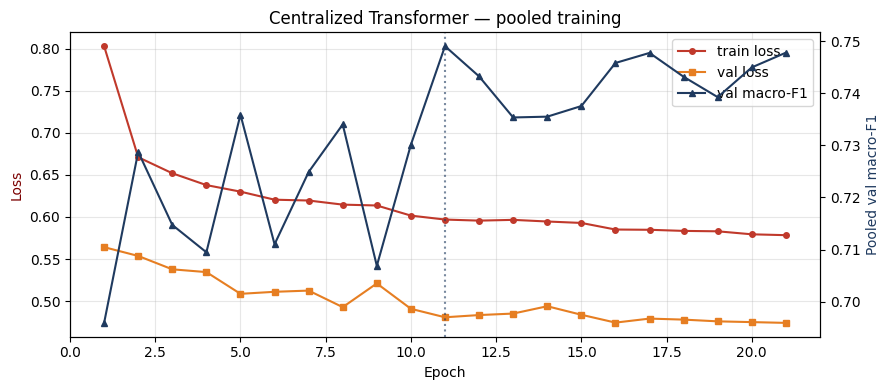

In [67]:
# 5.4 — Centralized training behavior: summary + curve
best_row = centralized_history_df.loc[centralized_history_df["val_macro_f1"].idxmax()]
centralized_train_summary_df = pd.DataFrame([{
    "Epochs_run": len(centralized_history_df), "Best_epoch": int(best_row["epoch"]),
    "Init_train_loss": round(centralized_history_df["train_loss"].iloc[0], 4),
    "Final_train_loss": round(centralized_history_df["train_loss"].iloc[-1], 4),
    "Init_val_loss": round(centralized_history_df["val_loss"].iloc[0], 4),
    "Best_val_loss": round(centralized_history_df["val_loss"].min(), 4),
    "Best_pooled_val_macro_F1": round(best_row["val_macro_f1"], 4),
    "Best_val_accuracy": round(best_row["val_accuracy"], 4)}])
centralized_train_summary_df.to_csv(AUDIT_DIR / "centralized_transformer_training_summary.csv", index=False)
print("Centralized Transformer training summary:")
display(centralized_train_summary_df)

fig, ax = plt.subplots(figsize=(9, 4)); ax2 = ax.twinx()
ax.plot(centralized_history_df["epoch"], centralized_history_df["train_loss"], "o-", color="#C0392B", ms=4, label="train loss")
ax.plot(centralized_history_df["epoch"], centralized_history_df["val_loss"], "s-", color="#E67E22", ms=4, label="val loss")
ax2.plot(centralized_history_df["epoch"], centralized_history_df["val_macro_f1"], "^-", color="#1F3A5F", ms=4, label="val macro-F1")
ax2.axvline(best_row["epoch"], color="#1F3A5F", ls=":", alpha=0.6)
ax.set_xlabel("Epoch"); ax.set_ylabel("Loss", color="#7B0000")
ax2.set_ylabel("Pooled val macro-F1", color="#1F3A5F"); ax.set_title("Centralized Transformer — pooled training")
ax.grid(True, alpha=0.3)
l1,la1 = ax.get_legend_handles_labels(); l2,la2 = ax2.get_legend_handles_labels()
ax.legend(l1+l2, la1+la2, loc="best")
plt.tight_layout()
plt.savefig(AUDIT_DIR / "centralized_transformer_training_curves.png", dpi=120, bbox_inches="tight")
plt.show()

In [68]:
# 5.5 — Centralized Transformer test evaluation, per client
centralized_test_rows = []; centralized_per_class = []; centralized_predictions = {}
for client in ACTIVE_CLIENTS:
    y_true = data[client]["test"]["y"]
    y_pred, y_proba = predict(centralized_model, data[client]["test"]["X"])
    centralized_predictions[client] = {"y_true": y_true, "y_pred": y_pred, "y_proba": y_proba}
    m = compute_test_metrics(y_true, y_pred)
    centralized_test_rows.append({
        "Client": client, "N_test": len(y_true),
        "Accuracy": round(m["accuracy"], 4), "Balanced_accuracy": round(m["balanced_accuracy"], 4),
        "Macro_F1_all_classes": round(m["macro_f1_all_classes"], 4),
        "Macro_F1_present_classes": round(m["macro_f1_present_classes"], 4),
        "Weighted_F1": round(m["weighted_f1"], 4), "Present_classes": m["present_classes"]})
    rep = classification_report(y_true, y_pred, labels=list(range(N_CLASSES)),
                                target_names=CLASS_NAMES, zero_division=0, output_dict=True)
    for cid, cname in enumerate(CLASS_NAMES):
        centralized_per_class.append({"Client": client, "Class_id": cid, "Class": cname,
            "Support": int(rep[cname]["support"]), "Precision": round(rep[cname]["precision"], 4),
            "Recall": round(rep[cname]["recall"], 4), "F1": round(rep[cname]["f1-score"], 4)})
centralized_test_df = pd.DataFrame(centralized_test_rows)
centralized_per_class_df = pd.DataFrame(centralized_per_class)
print("Centralized Transformer — test summary:")
display(centralized_test_df)

Centralized Transformer — test summary:


,Client,N_test,Accuracy,Balanced_accuracy,Macro_F1_all_classes,Macro_F1_present_classes,Weighted_F1,Present_classes
0,England,11942,0.8057,0.6597,0.6719,0.6719,0.8081,"Excellent, Good, Fair, Marginal, Poor"
1,Ireland,5887,0.8960,0.5352,0.3123,0.5206,0.8990,"Excellent, Good, Fair"
2,USA,1979,0.9227,0.7553,0.3124,0.7810,0.9219,"Excellent, Good"


### Section 5 — reading

The centralized Transformer does not clearly improve over the local Transformer. It is lower than the local Transformer on England and USA, while it is slightly higher on Ireland.

This result is important because it repeats the pattern already observed with recurrent models: pooling all client data does not automatically give a better model. The clients have different distributions, so adding more data also adds heterogeneity. The centralized model is therefore useful as a reference point, but it is not a clear upper bound in practice.


## Section 6 — Federated baseline: FedAvg

This section evaluates three FedAvg variants using the same logic as the GRU and LSTM notebooks. The purpose is to check whether a global Transformer model can be learned collaboratively across England, Ireland, and USA without sharing raw data.

The variants differ in the class-weighting strategy and learning rate. This helps separate the effect of federated averaging from the effect of imbalance handling.


In [69]:
# 6.1 — FedAvg aggregation weights
total_train = sum(len(data[c]["train"]["y"]) for c in ACTIVE_CLIENTS)
aggregation_weights = {c: len(data[c]["train"]["y"]) / total_train for c in ACTIVE_CLIENTS}
print("FedAvg aggregation weights:")
for c, w in aggregation_weights.items():
    print(f"  {c:<8} {w:.4f}")

FedAvg aggregation weights:
  England  0.5689
  Ireland  0.2065
  USA      0.2246


In [70]:
# 6.2 — FL utilities
FL_BASE_CONFIG = {
    "num_rounds": 30, "local_epochs": 1, "batch_size": 256,
    "weight_decay": 1e-4, "gradient_clip_norm": 1.0,
    "early_stopping_patience": 10, "aggregation": "weighted_by_train_size",
}

def get_criterion_fedavg(variant, client):
    if variant["loss"] == "per_client_weighted":
        w, _ = inverse_frequency_weights(data[client]["train"]["y"])
        return nn.CrossEntropyLoss(weight=torch.tensor(w, device=device))
    if variant["loss"] == "pooled_weighted":
        return nn.CrossEntropyLoss(weight=torch.tensor(pooled_weights, device=device))
    if variant["loss"] == "unweighted":
        return nn.CrossEntropyLoss()
    raise ValueError(variant["loss"])


def local_update(global_model, client, variant, mu=0.0):
    local_model = TransformerClassifier(**MODEL_CONFIG).to(device)
    local_model.load_state_dict(copy.deepcopy(global_model.state_dict()))
    global_params = {n: p.detach().clone() for n, p in global_model.named_parameters()} if mu > 0 else None
    loader = make_loader(data[client]["train"]["X"], data[client]["train"]["y"],
                         variant["batch_size"], shuffle=True)
    criterion = get_criterion_fedavg(variant, client)
    optimizer = torch.optim.Adam(local_model.parameters(),
                                 lr=variant["learning_rate"], weight_decay=variant["weight_decay"])
    local_model.train()
    total_loss, total_samples = 0.0, 0
    for _ in range(variant["local_epochs"]):
        for X_batch, y_batch in loader:
            X_batch = X_batch.to(device); y_batch = y_batch.to(device)
            optimizer.zero_grad()
            logits = local_model(X_batch)
            loss = criterion(logits, y_batch)
            if mu > 0:
                prox = sum(torch.sum((p - global_params[n]) ** 2)
                           for n, p in local_model.named_parameters())
                loss = loss + (mu / 2.0) * prox
            loss.backward()
            torch.nn.utils.clip_grad_norm_(local_model.parameters(), variant["gradient_clip_norm"])
            optimizer.step()
            bs = X_batch.size(0); total_loss += loss.item() * bs; total_samples += bs
    return local_model.state_dict(), total_loss / total_samples


def fedavg_aggregate(client_states):
    new_state = copy.deepcopy(client_states[ACTIVE_CLIENTS[0]])
    for key in new_state.keys():
        new_state[key] = sum(aggregation_weights[c] * client_states[c][key].to(new_state[key].dtype)
                             for c in ACTIVE_CLIENTS)
    return new_state


def eval_global(model, split):
    rows = []
    for client in ACTIVE_CLIENTS:
        loader = make_loader(data[client][split]["X"], data[client][split]["y"],
                             FL_BASE_CONFIG["batch_size"], shuffle=False)
        res = evaluate(model, loader, criterion=None)
        rows.append({"Client": client, "Split": split, "Accuracy": res["accuracy"],
                     "Balanced_accuracy": res["balanced_accuracy"], "Macro_F1": res["macro_f1"],
                     "Weighted_F1": res["weighted_f1"]})
    return pd.DataFrame(rows)


def run_federated(variant, mu=0.0, label=""):
    global_model = TransformerClassifier(**MODEL_CONFIG).to(device)
    best_state, best_metric, best_round = None, -np.inf, 0
    rounds_without_improvement = 0; history = []
    for rnd in range(1, variant["num_rounds"] + 1):
        t0 = time.time()
        client_states, client_losses = {}, {}
        for client in ACTIVE_CLIENTS:
            sd, cl = local_update(global_model, client, variant, mu=mu)
            client_states[client] = sd; client_losses[client] = cl
        global_model.load_state_dict(fedavg_aggregate(client_states))
        val_df = eval_global(global_model, split="val")
        mean_val_f1 = val_df["Macro_F1"].mean()
        improved = mean_val_f1 > best_metric + 1e-6
        if improved:
            best_metric, best_round = mean_val_f1, rnd
            best_state = copy.deepcopy(global_model.state_dict())
            rounds_without_improvement = 0; marker = "*"
        else:
            rounds_without_improvement += 1; marker = ""
        row = {"round": rnd, "mean_client_train_loss": np.mean(list(client_losses.values())),
               "mean_val_macro_f1": mean_val_f1, "mean_val_accuracy": val_df["Accuracy"].mean(),
               "time_sec": time.time() - t0}
        for _, r in val_df.iterrows():
            row[f"{r['Client']}_val_macro_f1"] = r["Macro_F1"]
            row[f"{r['Client']}_val_accuracy"] = r["Accuracy"]
        history.append(row)
        if label:
            print(f"[{label}] r{rnd:02d} | train_loss={row['mean_client_train_loss']:.4f} | "
                  f"mean_val_F1={mean_val_f1:.4f} {marker}")
        if rounds_without_improvement >= variant["early_stopping_patience"]:
            if label:
                print(f"[{label}] early stop at round {rnd}. "
                      f"Best round = {best_round}, best mean val_F1 = {best_metric:.4f}")
            break
    if best_state is not None:
        global_model.load_state_dict(best_state)
    return global_model, pd.DataFrame(history), {
        "best_round": best_round, "best_mean_val_macro_f1": best_metric, "n_rounds_run": len(history)}

In [71]:
# 6.3 — Run the three FedAvg variants (mirroring GRU/LSTM exactly)
fedavg_variants = {
    "FedAvg_v1": {**FL_BASE_CONFIG, "loss": "per_client_weighted", "learning_rate": 1e-3},
    "FedAvg_v2": {**FL_BASE_CONFIG, "loss": "pooled_weighted",     "learning_rate": 5e-4},
    "FedAvg_v3": {**FL_BASE_CONFIG, "loss": "unweighted",          "learning_rate": 5e-4},
}
fedavg_models = {}; fedavg_histories = {}; fedavg_summaries = {}
for name, variant in fedavg_variants.items():
    print(f"\n=== {name} | loss={variant['loss']} | lr={variant['learning_rate']} ===")
    m, h, s = run_federated(variant, mu=0.0, label=name)
    fedavg_models[name] = m; fedavg_histories[name] = h; fedavg_summaries[name] = {**s, **variant}
fedavg_summary_df = pd.DataFrame([
    {"Variant": name, "Loss": s["loss"], "Learning_rate": s["learning_rate"],
     "Best_round": s["best_round"], "Best_mean_val_F1": round(s["best_mean_val_macro_f1"], 4),
     "Rounds_run": s["n_rounds_run"]}
    for name, s in fedavg_summaries.items()])
print("\nFedAvg Transformer sweep — validation summary:")
display(fedavg_summary_df)


=== FedAvg_v1 | loss=per_client_weighted | lr=0.001 ===
[FedAvg_v1] r01 | train_loss=0.9945 | mean_val_F1=0.1430 *
[FedAvg_v1] r02 | train_loss=0.9443 | mean_val_F1=0.1542 *
[FedAvg_v1] r03 | train_loss=0.9463 | mean_val_F1=0.1500 
[FedAvg_v1] r04 | train_loss=0.9215 | mean_val_F1=0.1477 
[FedAvg_v1] r05 | train_loss=0.9067 | mean_val_F1=0.1378 
[FedAvg_v1] r06 | train_loss=0.8930 | mean_val_F1=0.1535 
[FedAvg_v1] r07 | train_loss=0.8838 | mean_val_F1=0.1496 
[FedAvg_v1] r08 | train_loss=0.8775 | mean_val_F1=0.1539 
[FedAvg_v1] r09 | train_loss=0.8932 | mean_val_F1=0.1500 
[FedAvg_v1] r10 | train_loss=0.8952 | mean_val_F1=0.1531 
[FedAvg_v1] r11 | train_loss=0.8883 | mean_val_F1=0.1639 *
[FedAvg_v1] r12 | train_loss=0.8838 | mean_val_F1=0.1518 
[FedAvg_v1] r13 | train_loss=0.8973 | mean_val_F1=0.1685 *
[FedAvg_v1] r14 | train_loss=0.8911 | mean_val_F1=0.1610 
[FedAvg_v1] r15 | train_loss=0.8827 | mean_val_F1=0.1694 *
[FedAvg_v1] r16 | train_loss=0.8843 | mean_val_F1=0.1770 *
[FedAvg_v

,Variant,Loss,Learning_rate,Best_round,Best_mean_val_F1,Rounds_run
0,FedAvg_v1,per_client_weighted,0.0010,30,0.1832,30
1,FedAvg_v2,pooled_weighted,0.0005,1,0.2195,11
2,FedAvg_v3,unweighted,0.0005,9,0.1569,19


### Section 6 — reading

FedAvg_v2 is selected by validation mean macro-F1. However, the selected FedAvg Transformer remains weaker than the local and centralized Transformer models on all clients.

The result shows that the attention-based architecture does not remove the difficulty of federated learning in this dataset. The global model still struggles to satisfy clients with different class distributions and different feature patterns.


## Section 7 — Federated extension: FedProx

Three FedProx variants (µ ∈ {0.01, 0.001, 0.0001}), mirroring the GRU and LSTM
sweeps. Same diagnostic question: does proximal regularization at any level
rescue the federated Transformer?


In [72]:
# 7.1 — Run the three FedProx variants
fedprox_variants = {
    "FedProx_v1": {**FL_BASE_CONFIG, "loss": "unweighted", "learning_rate": 5e-4, "mu": 0.01},
    "FedProx_v2": {**FL_BASE_CONFIG, "loss": "unweighted", "learning_rate": 5e-4, "mu": 0.001},
    "FedProx_v3": {**FL_BASE_CONFIG, "loss": "unweighted", "learning_rate": 5e-4, "mu": 0.0001},
}
fedprox_models = {}; fedprox_histories = {}; fedprox_summaries = {}
for name, variant in fedprox_variants.items():
    print(f"\n=== {name} | mu={variant['mu']} ===")
    m, h, s = run_federated(variant, mu=variant["mu"], label=name)
    fedprox_models[name] = m; fedprox_histories[name] = h; fedprox_summaries[name] = {**s, **variant}
fedprox_summary_df = pd.DataFrame([
    {"Variant": name, "Mu": s["mu"], "Learning_rate": s["learning_rate"],
     "Best_round": s["best_round"], "Best_mean_val_F1": round(s["best_mean_val_macro_f1"], 4),
     "Rounds_run": s["n_rounds_run"]}
    for name, s in fedprox_summaries.items()])
print("\nFedProx Transformer sweep — validation summary:")
display(fedprox_summary_df)


=== FedProx_v1 | mu=0.01 ===
[FedProx_v1] r01 | train_loss=0.5701 | mean_val_F1=0.1918 *
[FedProx_v1] r02 | train_loss=0.4348 | mean_val_F1=0.1025 
[FedProx_v1] r03 | train_loss=0.4327 | mean_val_F1=0.1036 
[FedProx_v1] r04 | train_loss=0.4339 | mean_val_F1=0.1200 
[FedProx_v1] r05 | train_loss=0.4365 | mean_val_F1=0.1097 
[FedProx_v1] r06 | train_loss=0.4251 | mean_val_F1=0.1138 
[FedProx_v1] r07 | train_loss=0.4308 | mean_val_F1=0.1222 
[FedProx_v1] r08 | train_loss=0.4292 | mean_val_F1=0.1077 
[FedProx_v1] r09 | train_loss=0.4278 | mean_val_F1=0.1114 
[FedProx_v1] r10 | train_loss=0.4277 | mean_val_F1=0.1360 
[FedProx_v1] r11 | train_loss=0.4303 | mean_val_F1=0.1221 
[FedProx_v1] early stop at round 11. Best round = 1, best mean val_F1 = 0.1918

=== FedProx_v2 | mu=0.001 ===
[FedProx_v2] r01 | train_loss=0.4939 | mean_val_F1=0.1503 *
[FedProx_v2] r02 | train_loss=0.4204 | mean_val_F1=0.1108 
[FedProx_v2] r03 | train_loss=0.4183 | mean_val_F1=0.1270 
[FedProx_v2] r04 | train_loss=0.

,Variant,Mu,Learning_rate,Best_round,Best_mean_val_F1,Rounds_run
0,FedProx_v1,0.0100,0.0005,1,0.1918,11
1,FedProx_v2,0.0010,0.0005,1,0.1503,11
2,FedProx_v3,0.0001,0.0005,7,0.1487,17


### Section 7 — reading

FedProx changes the federated behavior, but it does not solve the problem. FedProx_v1 performs better than the selected FedAvg variant on Ireland and USA, but it remains below the non-federated Transformer baselines and performs poorly on England.

This means that proximal regularization can modify the failure pattern, but it is not enough to make the federated Transformer competitive with local or centralized training. The main difficulty remains linked to client heterogeneity and imbalance.


## Section 8 — Federated training-side analysis

Per-client validation macro-F1 over rounds, all six variants.


In [73]:
# 8.1 — Combined federated validation comparison
all_fed_summaries = {**fedavg_summaries, **fedprox_summaries}
federated_validation_df = pd.DataFrame([
    {"Variant": name, "Family": "FedAvg" if name.startswith("FedAvg") else "FedProx",
     "Loss": s["loss"], "Learning_rate": s["learning_rate"], "Mu": s.get("mu", None),
     "Best_round": s["best_round"], "Best_mean_val_F1": round(s["best_mean_val_macro_f1"], 4),
     "Rounds_run": s["n_rounds_run"]}
    for name, s in all_fed_summaries.items()])
federated_validation_df = federated_validation_df.sort_values("Best_mean_val_F1", ascending=False).reset_index(drop=True)
print("All federated Transformer variants — validation comparison:")
display(federated_validation_df)
best_fedavg_name  = max(fedavg_summaries, key=lambda k: fedavg_summaries[k]["best_mean_val_macro_f1"])
best_fedprox_name = max(fedprox_summaries, key=lambda k: fedprox_summaries[k]["best_mean_val_macro_f1"])
print(f"\nBest FedAvg Transformer  : {best_fedavg_name}")
print(f"Best FedProx Transformer : {best_fedprox_name}")

All federated Transformer variants — validation comparison:


,Variant,Family,Loss,Learning_rate,Mu,Best_round,Best_mean_val_F1,Rounds_run
0,FedAvg_v2,FedAvg,pooled_weighted,0.0005,NaN,1,0.2195,11
1,FedProx_v1,FedProx,unweighted,0.0005,0.0100,1,0.1918,11
2,FedAvg_v1,FedAvg,per_client_weighted,0.0010,NaN,30,0.1832,30
3,FedAvg_v3,FedAvg,unweighted,0.0005,NaN,9,0.1569,19
4,FedProx_v2,FedProx,unweighted,0.0005,0.0010,1,0.1503,11
5,FedProx_v3,FedProx,unweighted,0.0005,0.0001,7,0.1487,17



Best FedAvg Transformer  : FedAvg_v2
Best FedProx Transformer : FedProx_v1


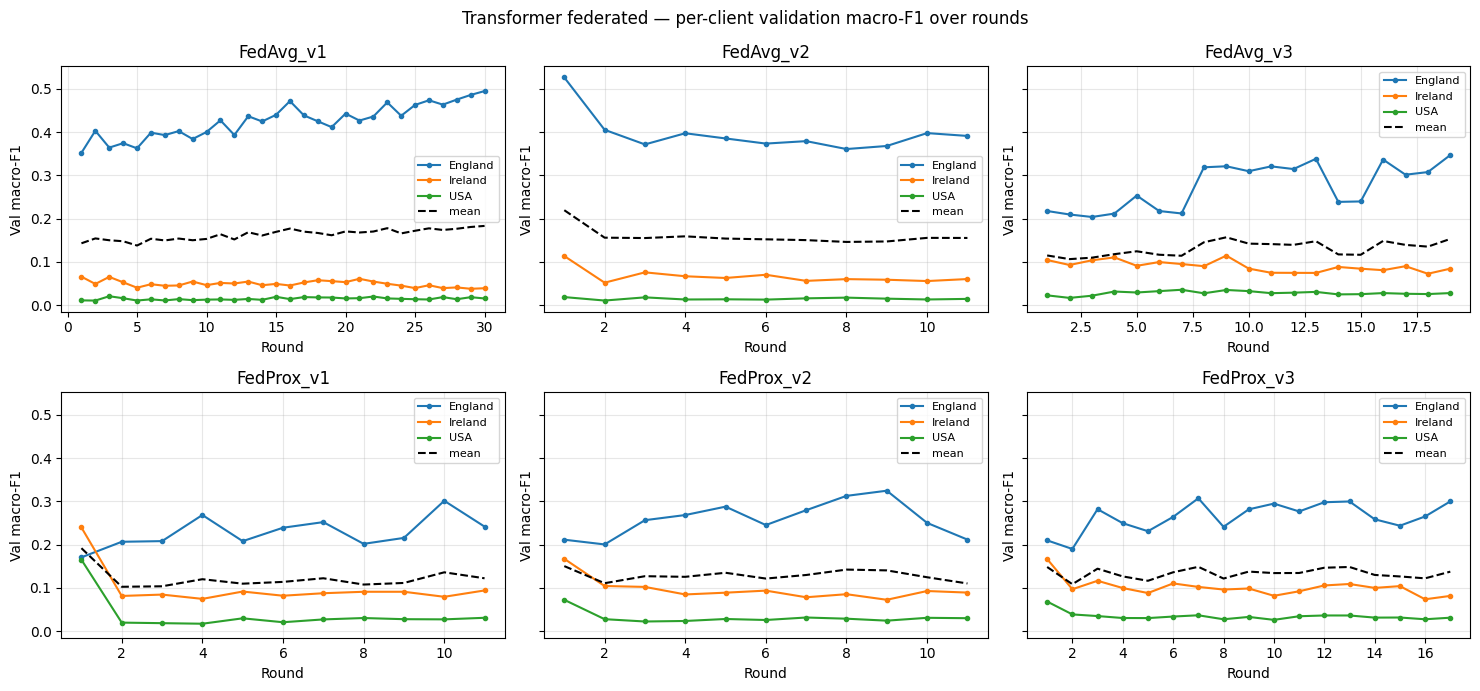

In [74]:
# 8.2 — Per-client validation curves across rounds
all_fed_histories = {**fedavg_histories, **fedprox_histories}
fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharey=True)
variant_order = ["FedAvg_v1","FedAvg_v2","FedAvg_v3","FedProx_v1","FedProx_v2","FedProx_v3"]
for ax, name in zip(axes.flat, variant_order):
    hist = all_fed_histories[name]
    for client in ACTIVE_CLIENTS:
        col = f"{client}_val_macro_f1"
        if col in hist.columns:
            ax.plot(hist["round"], hist[col], marker="o", markersize=3, label=client)
    ax.plot(hist["round"], hist["mean_val_macro_f1"], "--", color="black", label="mean", linewidth=1.5)
    ax.set_title(name); ax.set_xlabel("Round"); ax.set_ylabel("Val macro-F1")
    ax.legend(loc="best", fontsize=8); ax.grid(True, alpha=0.3)
plt.suptitle("Transformer federated — per-client validation macro-F1 over rounds")
plt.tight_layout()
plt.savefig(AUDIT_DIR / "federated_transformer_val_curves.png", dpi=120, bbox_inches="tight")
plt.show()

### Section 8 — reading

The federated training curves show unstable behavior. Most variants reach their best mean validation score very early, while FedAvg_v1 continues until round 30 without becoming a strong test model.

This supports the same interpretation as the GRU and LSTM experiments: the federated problem is not solved by changing the model family. The global model is affected by the non-IID client setting, where England, Ireland, and USA do not require exactly the same decision boundary.


## Section 9 — Federated test evaluation

9.1 evaluates the best FedAvg and best FedProx (for the three-way comparison);
9.2 evaluates all six variants (for the matched cross-architecture comparison).


In [75]:
# 9.1 — Test eval of best FedAvg and best FedProx
def federated_test_eval(model, label):
    rows, pc_rows, preds_store = [], [], {}
    for client in ACTIVE_CLIENTS:
        y_true = data[client]["test"]["y"]
        y_pred, y_proba = predict(model, data[client]["test"]["X"])
        preds_store[client] = {"y_true": y_true, "y_pred": y_pred, "y_proba": y_proba}
        m = compute_test_metrics(y_true, y_pred)
        rows.append({"Variant": label, "Client": client, "N_test": len(y_true),
            "Accuracy": round(m["accuracy"], 4), "Balanced_accuracy": round(m["balanced_accuracy"], 4),
            "Macro_F1_all_classes": round(m["macro_f1_all_classes"], 4),
            "Macro_F1_present_classes": round(m["macro_f1_present_classes"], 4),
            "Weighted_F1": round(m["weighted_f1"], 4), "Present_classes": m["present_classes"]})
        rep = classification_report(y_true, y_pred, labels=list(range(N_CLASSES)),
                                    target_names=CLASS_NAMES, zero_division=0, output_dict=True)
        for cid, cname in enumerate(CLASS_NAMES):
            pc_rows.append({"Variant": label, "Client": client, "Class_id": cid, "Class": cname,
                "Support": int(rep[cname]["support"]), "Precision": round(rep[cname]["precision"], 4),
                "Recall": round(rep[cname]["recall"], 4), "F1": round(rep[cname]["f1-score"], 4)})
    return rows, pc_rows, preds_store

fedavg_test_rows,  fedavg_per_class_rows,  fedavg_predictions  = federated_test_eval(fedavg_models[best_fedavg_name], best_fedavg_name)
fedprox_test_rows, fedprox_per_class_rows, fedprox_predictions = federated_test_eval(fedprox_models[best_fedprox_name], best_fedprox_name)
federated_test_df = pd.DataFrame(fedavg_test_rows + fedprox_test_rows)
federated_per_class_df = pd.DataFrame(fedavg_per_class_rows + fedprox_per_class_rows)
print("Best FedAvg and best FedProx Transformer — test summary:")
display(federated_test_df)

Best FedAvg and best FedProx Transformer — test summary:


,Variant,Client,N_test,Accuracy,Balanced_accuracy,Macro_F1_all_classes,Macro_F1_present_classes,Weighted_F1,Present_classes
0,FedAvg_v2,England,11942,0.5483,0.3863,0.3882,0.3882,0.5082,"Excellent, Good, Fair, Marginal, Poor"
1,FedAvg_v2,Ireland,5887,0.2609,0.4873,0.1088,0.1814,0.3494,"Excellent, Good, Fair"
2,FedAvg_v2,USA,1979,0.1430,0.1923,0.0586,0.1464,0.2119,"Excellent, Good"
3,FedProx_v1,England,11942,0.3755,0.2442,0.1845,0.1845,0.2410,"Excellent, Good, Fair, Marginal, Poor"
4,FedProx_v1,Ireland,5887,0.6147,0.5120,0.2362,0.3936,0.6822,"Excellent, Good, Fair"
5,FedProx_v1,USA,1979,0.5856,0.5627,0.1899,0.4747,0.6804,"Excellent, Good"


In [76]:
# 9.2 — Evaluate all six variants on test
all_fed_models = {**fedavg_models, **fedprox_models}
all_variants_test_rows = []; all_variants_per_class_rows = []
for variant_name, model in all_fed_models.items():
    s = all_fed_summaries[variant_name]
    family = "FedAvg" if variant_name.startswith("FedAvg") else "FedProx"
    for client in ACTIVE_CLIENTS:
        y_true = data[client]["test"]["y"]
        y_pred, _ = predict(model, data[client]["test"]["X"])
        m = compute_test_metrics(y_true, y_pred)
        all_variants_test_rows.append({
            "Variant": variant_name, "Family": family, "Loss": s["loss"],
            "Learning_rate": s["learning_rate"], "Mu": s.get("mu", None),
            "Best_round": s["best_round"], "Best_mean_val_macro_F1": round(s["best_mean_val_macro_f1"], 4),
            "Client": client, "N_test": len(y_true), "Accuracy": round(m["accuracy"], 4),
            "Balanced_accuracy": round(m["balanced_accuracy"], 4),
            "Macro_F1_all_classes": round(m["macro_f1_all_classes"], 4),
            "Macro_F1_present_classes": round(m["macro_f1_present_classes"], 4),
            "Weighted_F1": round(m["weighted_f1"], 4), "Present_classes": m["present_classes"]})
        rep = classification_report(y_true, y_pred, labels=list(range(N_CLASSES)),
                                    target_names=CLASS_NAMES, zero_division=0, output_dict=True)
        for cid, cname in enumerate(CLASS_NAMES):
            all_variants_per_class_rows.append({"Variant": variant_name, "Client": client,
                "Class_id": cid, "Class": cname, "Support": int(rep[cname]["support"]),
                "Precision": round(rep[cname]["precision"], 4), "Recall": round(rep[cname]["recall"], 4),
                "F1": round(rep[cname]["f1-score"], 4)})
all_variants_test_df = pd.DataFrame(all_variants_test_rows)
all_variants_per_class_df = pd.DataFrame(all_variants_per_class_rows)
print("All federated Transformer variants — per-client test summary:")
display(all_variants_test_df)

All federated Transformer variants — per-client test summary:


,Variant,Family,Loss,Learning_rate,Mu,Best_round,Best_mean_val_macro_F1,Client,N_test,Accuracy,Balanced_accuracy,Macro_F1_all_classes,Macro_F1_present_classes,Weighted_F1,Present_classes
0,FedAvg_v1,FedAvg,per_client_weighted,0.0010,NaN,30,0.1832,England,11942,0.4877,0.3975,0.4109,0.4109,0.4216,"Excellent, Good, Fair, Marginal, Poor"
1,FedAvg_v1,FedAvg,per_client_weighted,0.0010,NaN,30,0.1832,Ireland,5887,0.0717,0.3051,0.0307,0.0511,0.0162,"Excellent, Good, Fair"
2,FedAvg_v1,FedAvg,per_client_weighted,0.0010,NaN,30,0.1832,USA,1979,0.2046,0.2904,0.0809,0.2022,0.2848,"Excellent, Good"
3,FedAvg_v2,FedAvg,pooled_weighted,0.0005,NaN,1,0.2195,England,11942,0.5483,0.3863,0.3882,0.3882,0.5082,"Excellent, Good, Fair, Marginal, Poor"
4,FedAvg_v2,FedAvg,pooled_weighted,0.0005,NaN,1,0.2195,Ireland,5887,0.2609,0.4873,0.1088,0.1814,0.3494,"Excellent, Good, Fair"
5,FedAvg_v2,FedAvg,pooled_weighted,0.0005,NaN,1,0.2195,USA,1979,0.1430,0.1923,0.0586,0.1464,0.2119,"Excellent, Good"
6,FedAvg_v3,FedAvg,unweighted,0.0005,NaN,9,0.1569,England,11942,0.4042,0.2893,0.2633,0.2633,0.2930,"Excellent, Good, Fair, Marginal, Poor"
7,FedAvg_v3,FedAvg,unweighted,0.0005,NaN,9,0.1569,Ireland,5887,0.1140,0.4760,0.0897,0.1494,0.0243,"Excellent, Good, Fair"
8,FedAvg_v3,FedAvg,unweighted,0.0005,NaN,9,0.1569,USA,1979,0.2476,0.3972,0.0969,0.2422,0.3218,"Excellent, Good"
9,FedProx_v1,FedProx,unweighted,0.0005,0.0100,1,0.1918,England,11942,0.3755,0.2442,0.1845,0.1845,0.2410,"Excellent, Good, Fair, Marginal, Poor"


### Section 9 — reading

FedAvg_v2 is the selected FedAvg Transformer variant based on validation performance. On the test sets, it remains below the local and centralized Transformer models for all three clients, with the weakest behavior on Ireland and USA.

FedProx_v1 gives better test results on Ireland and USA than FedAvg_v2, but it is still below the non-federated baselines. Therefore, FedProx changes the distribution of errors but does not solve the main federated-learning difficulty.

The conclusion is that the Transformer is useful as an attention-based baseline, but the federated Transformer is not competitive with local or centralized Transformer training in the current Stage 1 setup.


## Section 10 — Three-way test comparison (Transformer)

Local, Centralized, and best Federated Transformer side by side, with delta
columns. This is the within-architecture comparison.


In [77]:
# 10.1 — Three-way comparison (Transformer)
three_way = []
for client in ACTIVE_CLIENTS:
    L = next(r for r in local_test_rows       if r["Client"] == client)
    C = next(r for r in centralized_test_rows if r["Client"] == client)
    F = next(r for r in fedavg_test_rows      if r["Client"] == client)
    three_way.append({"Client": client,
        "Local_macro_F1_present": L["Macro_F1_present_classes"],
        "Centralized_macro_F1_present": C["Macro_F1_present_classes"],
        "Federated_macro_F1_present": F["Macro_F1_present_classes"],
        "Local_accuracy": L["Accuracy"], "Centralized_accuracy": C["Accuracy"],
        "Federated_accuracy": F["Accuracy"],
        "Δ_Central_vs_Local": round(C["Macro_F1_present_classes"] - L["Macro_F1_present_classes"], 4),
        "Δ_Federated_vs_Local": round(F["Macro_F1_present_classes"] - L["Macro_F1_present_classes"], 4),
        "Δ_Central_vs_Federated": round(C["Macro_F1_present_classes"] - F["Macro_F1_present_classes"], 4)})
three_way_df = pd.DataFrame(three_way)
print("Transformer three-way comparison (test set, present-class macro-F1):")
display(three_way_df)

Transformer three-way comparison (test set, present-class macro-F1):


,Client,Local_macro_F1_present,Centralized_macro_F1_present,Federated_macro_F1_present,Local_accuracy,Centralized_accuracy,Federated_accuracy,Δ_Central_vs_Local,Δ_Federated_vs_Local,Δ_Central_vs_Federated
0,England,0.7091,0.6719,0.3882,0.8122,0.8057,0.5483,-0.0372,-0.3209,0.2837
1,Ireland,0.4955,0.5206,0.1814,0.8663,0.8960,0.2609,0.0251,-0.3141,0.3392
2,USA,0.7896,0.7810,0.1464,0.9222,0.9227,0.1430,-0.0086,-0.6432,0.6346


### Section 10 — reading

The within-Transformer comparison gives the same main ordering observed in the previous notebooks. Local and centralized Transformer results are close, while the selected federated Transformer is clearly lower on every client.

For England, the local Transformer is stronger than the centralized Transformer. For Ireland, the centralized Transformer is slightly stronger. For USA, the two non-federated results are almost identical. In contrast, the federated Transformer is far below both non-federated settings, especially on USA.

This section should be read as a Transformer-specific result only. The full ranking across all model families is kept for Notebook 09.


## Section 11 — Modal-density-stratified evaluation (Transformer)

Same protocol as Notebooks 03 and 04.


In [78]:
# 11.1 — Compute per-sequence modal density
def per_sequence_modal_density(mask):
    N = mask.shape[0]
    return mask.reshape(N, -1).mean(axis=1)
modal_density = {}; modal_threshold = {}
for client in ACTIVE_CLIENTS:
    md_test = per_sequence_modal_density(data[client]["test"]["mask"])
    modal_density[client] = md_test
    modal_threshold[client] = float(np.median(md_test))
    print(f"{client:<8}: median test modal density = {modal_threshold[client]:.4f}")

England : median test modal density = 0.2396
Ireland : median test modal density = 0.3021
USA     : median test modal density = 0.6979


In [79]:
# 11.2 — Stratify each Transformer model's predictions
def stratified_metrics(client, predictions_for_client):
    md = modal_density[client]; thr = modal_threshold[client]
    low_idx = md < thr; high_idx = md >= thr
    out = []
    for label, idx in [("Low_modal_density", low_idx), ("High_modal_density", high_idx)]:
        y_true = predictions_for_client["y_true"][idx]; y_pred = predictions_for_client["y_pred"][idx]
        if len(y_true) == 0: continue
        m = compute_test_metrics(y_true, y_pred)
        out.append({"Stratum": label, "N": int(idx.sum()), "Accuracy": round(m["accuracy"], 4),
            "Macro_F1_present_classes": round(m["macro_f1_present_classes"], 4),
            "Weighted_F1": round(m["weighted_f1"], 4)})
    return out
stratified_rows = []
for model_label, preds in [("Local Transformer", local_predictions),
                           ("Centralized Transformer", centralized_predictions),
                           (f"{best_fedavg_name} Transformer", fedavg_predictions)]:
    for client in ACTIVE_CLIENTS:
        for s in stratified_metrics(client, preds[client]):
            stratified_rows.append({"Model": model_label, "Client": client, **s})
stratified_df = pd.DataFrame(stratified_rows)
print("Transformer modal-density-stratified evaluation:")
display(stratified_df)

Transformer modal-density-stratified evaluation:


,Model,Client,Stratum,N,Accuracy,Macro_F1_present_classes,Weighted_F1
0,Local Transformer,England,Low_modal_density,5966,0.7821,0.5849,0.7841
1,Local Transformer,England,High_modal_density,5976,0.8422,0.7372,0.8429
2,Local Transformer,Ireland,Low_modal_density,2908,0.7792,0.4800,0.7985
3,Local Transformer,Ireland,High_modal_density,2979,0.9513,0.4652,0.9496
4,Local Transformer,USA,Low_modal_density,954,0.8700,0.7955,0.8716
5,Local Transformer,USA,High_modal_density,1025,0.9707,0.4926,0.9611
6,Centralized Transformer,England,Low_modal_density,5966,0.7782,0.5779,0.7817
7,Centralized Transformer,England,High_modal_density,5976,0.8332,0.6945,0.8344
8,Centralized Transformer,Ireland,Low_modal_density,2908,0.8370,0.5217,0.8452
9,Centralized Transformer,Ireland,High_modal_density,2979,0.9537,0.4376,0.9473


### Section 11 — reading

The modal-density analysis confirms that accuracy alone can be misleading. On Ireland and USA, high-modal-density sequences often show higher accuracy because they are strongly dominated by the Excellent class. However, present-class macro-F1 drops in the high-density group, especially for USA.

For example, the local Transformer on USA goes from 0.7955 macro-F1 in the low-modal-density group to 0.4926 in the high-modal-density group. This means that the model performs less well in a class-balanced sense when the input contains many repeated/modal-value patterns.

The same behavior was already observed with GRU and LSTM. Therefore, the modal-density effect is not specific to the Transformer; it is a data-quality and class-distribution issue.


## Section 12 — Capacity ablation (centralized only)

Does the Transformer's behaviour change with model width? We train the
centralized Transformer at three capacities, holding dimensions-per-head
constant at 16 (so only total width varies, not per-head capacity):

| d_model | nhead | dims/head |
|---|---|---|
| 32 | 2 | 16 |
| 64 | 4 | 16 |
| 128 | 8 | 16 |

The centralized setting is the strongest case (pooled data, no federation
penalty). The logic: if more capacity does not help even the centralized
Transformer, it will not help the federated one. The d_model = 64 row reuses
the centralized model already trained in Section 5; d_model = 32 and 128 are
trained fresh here. These swept versions are reported only in this section
and never enter the cross-architecture comparison.


In [80]:
# 12.1 — Capacity ablation: train d_model in {32, 128}, reuse 64 from Section 5
capacity_rows = []

# d_model = 64 row reused from Section 5 (already trained, consistent everywhere)
n_params_64 = count_trainable_parameters(TransformerClassifier(**MODEL_CONFIG))
for r in centralized_test_rows:
    capacity_rows.append({
        "d_model": 64, "nhead": 4, "n_params": n_params_64, "Client": r["Client"],
        "Accuracy": r["Accuracy"], "Macro_F1_present_classes": r["Macro_F1_present_classes"],
        "Weighted_F1": r["Weighted_F1"]})

# d_model in {32, 128} trained fresh on the same pooled data
ablation_configs = [{"d_model": 32, "nhead": 2}, {"d_model": 128, "nhead": 8}]
capacity_models = {64: centralized_model}
for cfg in ablation_configs:
    mc = {**MODEL_CONFIG, **cfg}
    print(f"\n=== Capacity ablation: d_model={cfg['d_model']}, nhead={cfg['nhead']} ===")
    model = TransformerClassifier(**mc).to(device)
    model, _, _ = train_supervised(model, train_loader_c, val_loader_c,
                                   criterion_central, label=f"d{cfg['d_model']}")
    capacity_models[cfg["d_model"]] = model
    np_count = count_trainable_parameters(model)
    for client in ACTIVE_CLIENTS:
        y_true = data[client]["test"]["y"]
        y_pred, _ = predict(model, data[client]["test"]["X"])
        m = compute_test_metrics(y_true, y_pred)
        capacity_rows.append({
            "d_model": cfg["d_model"], "nhead": cfg["nhead"], "n_params": np_count,
            "Client": client, "Accuracy": round(m["accuracy"], 4),
            "Macro_F1_present_classes": round(m["macro_f1_present_classes"], 4),
            "Weighted_F1": round(m["weighted_f1"], 4)})

capacity_df = pd.DataFrame(capacity_rows).sort_values(["d_model", "Client"]).reset_index(drop=True)
capacity_df.to_csv(AUDIT_DIR / "transformer_capacity_ablation.csv", index=False)
print("\nCapacity ablation (centralized Transformer, per client):")
display(capacity_df)

# Mean across clients per capacity
capacity_mean = (capacity_df.groupby(["d_model", "nhead", "n_params"], as_index=False)
                 ["Macro_F1_present_classes"].mean().round(4))
print("\nCapacity ablation — mean present-class macro-F1 across clients:")
display(capacity_mean)


=== Capacity ablation: d_model=32, nhead=2 ===
[d32] ep 01 | train_loss=0.8834 | val_macro_f1=0.6472 | val_acc=0.7117 *
[d32] ep 02 | train_loss=0.7111 | val_macro_f1=0.6992 | val_acc=0.7687 *
[d32] ep 03 | train_loss=0.6731 | val_macro_f1=0.7102 | val_acc=0.7905 *
[d32] ep 04 | train_loss=0.6603 | val_macro_f1=0.7193 | val_acc=0.8061 *
[d32] ep 05 | train_loss=0.6513 | val_macro_f1=0.7388 | val_acc=0.8251 *
[d32] ep 06 | train_loss=0.6421 | val_macro_f1=0.7219 | val_acc=0.8074 
[d32] ep 07 | train_loss=0.6385 | val_macro_f1=0.7386 | val_acc=0.8302 
[d32] ep 08 | train_loss=0.6342 | val_macro_f1=0.7470 | val_acc=0.8334 *
[d32] ep 09 | train_loss=0.6285 | val_macro_f1=0.7314 | val_acc=0.8333 
[d32] ep 10 | train_loss=0.6273 | val_macro_f1=0.7393 | val_acc=0.8258 
[d32] ep 11 | train_loss=0.6226 | val_macro_f1=0.7301 | val_acc=0.8162 
[d32] ep 12 | train_loss=0.6196 | val_macro_f1=0.7371 | val_acc=0.8267 
[d32] ep 13 | train_loss=0.6118 | val_macro_f1=0.7409 | val_acc=0.8243 
[d32] ep 1

,d_model,nhead,n_params,Client,Accuracy,Macro_F1_present_classes,Weighted_F1
0,32,2,25861,England,0.7995,0.6869,0.8023
1,32,2,25861,Ireland,0.8989,0.5152,0.9000
2,32,2,25861,USA,0.9192,0.7573,0.9177
3,64,4,67845,England,0.8057,0.6719,0.8081
4,64,4,67845,Ireland,0.8960,0.5206,0.8990
5,64,4,67845,USA,0.9227,0.7810,0.9219
6,128,8,200965,England,0.7815,0.6676,0.7813
7,128,8,200965,Ireland,0.9086,0.4983,0.9011
8,128,8,200965,USA,0.9298,0.7993,0.9282



Capacity ablation — mean present-class macro-F1 across clients:


,d_model,nhead,n_params,Macro_F1_present_classes
0,32,2,25861,0.6531
1,64,4,67845,0.6578
2,128,8,200965,0.6551


### Section 12 — reading

The capacity ablation shows that increasing the Transformer width does not meaningfully improve the result. The mean present-class macro-F1 remains almost flat across the three capacities: d_model = 32, 64, and 128.

The canonical d_model = 64 gives the best mean score, but the difference from the smaller and larger models is very small. This means the Transformer is not weak because it is too small. Increasing model capacity does not solve the main limitation.

This is useful for the thesis defense because it answers the possible objection that the Transformer needed a bigger architecture.


## Section 13 — Design ablation: alternative Transformer design (centralized only)

The canonical Transformer used in this notebook follows the simplest
sequence-classification design — mean-pool read-out, sinusoidal positional
encoding, post-norm encoder layers, and the Adam optimizer — chosen so that
the model body is the only thing differing from the recurrent GRU and LSTM
baselines.

A reviewer may reasonably ask whether more modern Transformer design
choices would change the Stage-1 conclusion. This section answers that
question by training one **alternative-design** Transformer that bundles
the four design choices most commonly found in current Transformer
classifiers, and comparing it to the canonical Transformer at otherwise
identical settings.

| Choice | Canonical | Alternative |
|---|---|---|
| Read-out | mean-pool over the 12 months | learnable CLS token |
| Positional encoding | sinusoidal (fixed) | learnable embeddings |
| Encoder normalization | post-norm (default) | pre-norm |
| Optimizer | Adam | AdamW |

**Crucially, all other hyperparameters remain matched** — batch size 256,
max 50 epochs, patience 10, dropout 0.2, learning rate 1e-3, weight decay
1e-4, gradient clip 1.0. Only the four design choices above change. This
isolates the design effect from any training-protocol differences.

The ablation is run on the **centralized** setting only, because that is
the best-case scenario (pooled data, no federation penalty). The logic: if
the modern design does not help even the centralized Transformer, it will
not help the federated one. The d_model is fixed at 64 to match the
canonical Transformer in the three-architecture comparison.


In [81]:
# 13.1 — Alternative-design Transformer classifier
class AlternativeTransformerClassifier(nn.Module):
    """Alternative Transformer design:
       - CLS token read-out (instead of mean-pool)
       - Learnable positional embeddings (instead of sinusoidal)
       - Pre-norm encoder layers (norm_first=True)
       - GELU activation (kept explicit for clarity)
    """
    def __init__(self, input_size=N_FEATS, d_model=64, nhead=4,
                 num_layers=2, dim_feedforward=128, num_classes=N_CLASSES,
                 dropout=0.2, window=WINDOW):
        super().__init__()
        self.input_proj = nn.Linear(input_size, d_model)

        # Learnable CLS token and learnable positional embeddings (one per
        # position, including the CLS position at index 0)
        self.cls_token = nn.Parameter(torch.zeros(1, 1, d_model))
        self.pos_embed = nn.Parameter(torch.zeros(1, window + 1, d_model))

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=dim_feedforward,
            dropout=dropout,
            activation="gelu",
            batch_first=True,
            norm_first=True,            # pre-norm
        )
        self.encoder    = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)
        self.norm       = nn.LayerNorm(d_model)
        self.classifier = nn.Sequential(nn.Dropout(dropout), nn.Linear(d_model, num_classes))

        # Init the new learnable parameters
        nn.init.trunc_normal_(self.cls_token, std=0.02)
        nn.init.trunc_normal_(self.pos_embed, std=0.02)

    def forward(self, x):
        batch_size = x.shape[0]
        x = self.input_proj(x)                            # (batch, 12, d_model)
        cls = self.cls_token.expand(batch_size, -1, -1)   # (batch, 1, d_model)
        x = torch.cat([cls, x], dim=1)                    # (batch, 13, d_model)
        x = x + self.pos_embed[:, : x.shape[1], :]        # add learnable PE
        x = self.encoder(x)
        cls_out = self.norm(x[:, 0, :])                   # read out the CLS position
        return self.classifier(cls_out)


# Smoke test
_alt_smoke = AlternativeTransformerClassifier().to(device)
_n_alt = count_trainable_parameters(_alt_smoke)
_n_can = count_trainable_parameters(TransformerClassifier(**MODEL_CONFIG))
_smoke_x = torch.randn(4, WINDOW, N_FEATS).to(device)
_smoke_out = _alt_smoke(_smoke_x)
print(f"Alternative Transformer defined.")
print(f"  Parameters (alternative) : {_n_alt:,}")
print(f"  Parameters (canonical)   : {_n_can:,}")
print(f"  Smoke output shape       : {tuple(_smoke_out.shape)}")
assert _smoke_out.shape == (4, N_CLASSES)
del _alt_smoke, _smoke_x, _smoke_out
if torch.cuda.is_available():
    torch.cuda.empty_cache()

Alternative Transformer defined.
  Parameters (alternative) : 68,869
  Parameters (canonical)   : 67,845
  Smoke output shape       : (4, 5)


/tmp/ipykernel_58/2517057202.py:29: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder    = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)


In [82]:
# 13.2 — Train alternative-design Transformer on the centralized data
# (same matched hyperparameters as Section 5; only optimizer = AdamW)
def train_alternative_centralized():
    model = AlternativeTransformerClassifier(
        input_size=N_FEATS, d_model=MODEL_CONFIG["d_model"],
        nhead=MODEL_CONFIG["nhead"], num_layers=MODEL_CONFIG["num_layers"],
        dim_feedforward=MODEL_CONFIG["dim_feedforward"],
        num_classes=N_CLASSES, dropout=MODEL_CONFIG["dropout"], window=WINDOW,
    ).to(device)

    criterion = nn.CrossEntropyLoss(weight=torch.tensor(pooled_weights, device=device))
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=TRAIN_CONFIG["learning_rate"],
        weight_decay=TRAIN_CONFIG["weight_decay"],
    )
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max",
        factor=TRAIN_CONFIG["lr_scheduler_factor"],
        patience=TRAIN_CONFIG["lr_scheduler_patience"],
    )

    best_state, best_metric, best_epoch = None, -np.inf, 0
    epochs_without_improvement = 0
    history = []

    for epoch in range(1, TRAIN_CONFIG["max_epochs"] + 1):
        t0 = time.time()
        model.train()
        total_loss, total_samples = 0.0, 0
        for X_batch, y_batch in train_loader_c:
            X_batch = X_batch.to(device); y_batch = y_batch.to(device)
            optimizer.zero_grad()
            logits = model(X_batch)
            loss = criterion(logits, y_batch)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(),
                                           TRAIN_CONFIG["gradient_clip_norm"])
            optimizer.step()
            bs = X_batch.size(0); total_loss += loss.item() * bs; total_samples += bs
        train_loss = total_loss / total_samples

        val_metrics = evaluate(model, val_loader_c, criterion)
        val_macro_f1 = val_metrics["macro_f1"]
        scheduler.step(val_macro_f1)

        improved = val_macro_f1 > best_metric + 1e-6
        if improved:
            best_metric, best_epoch = val_macro_f1, epoch
            best_state = copy.deepcopy(model.state_dict())
            epochs_without_improvement = 0; marker = "*"
        else:
            epochs_without_improvement += 1; marker = ""

        history.append({
            "epoch": epoch, "train_loss": train_loss,
            "val_loss": val_metrics["loss"],
            "val_accuracy": val_metrics["accuracy"],
            "val_balanced_accuracy": val_metrics["balanced_accuracy"],
            "val_macro_f1": val_macro_f1,
            "val_weighted_f1": val_metrics["weighted_f1"],
            "learning_rate": optimizer.param_groups[0]["lr"],
            "time_sec": time.time() - t0,
        })
        print(f"[ALT-CENTR] ep {epoch:02d} | train_loss={train_loss:.4f} | "
              f"val_macro_f1={val_macro_f1:.4f} | val_acc={val_metrics['accuracy']:.4f} {marker}")

        if epochs_without_improvement >= TRAIN_CONFIG["early_stopping_patience"]:
            print(f"[ALT-CENTR] early stop at epoch {epoch}. "
                  f"Best epoch = {best_epoch}, best val_macro_f1 = {best_metric:.4f}")
            break

    if best_state is not None:
        model.load_state_dict(best_state)
    return model, pd.DataFrame(history), {
        "best_epoch": best_epoch, "best_val_macro_f1": best_metric,
        "n_epochs_run": len(history),
    }


alt_centralized_model, alt_centralized_history_df, alt_centralized_summary = (
    train_alternative_centralized()
)

print(f"\nAlternative-design centralized Transformer:")
print(f"  best epoch              : {alt_centralized_summary['best_epoch']}")
print(f"  best pooled val macro-F1: {alt_centralized_summary['best_val_macro_f1']:.4f}")

/tmp/ipykernel_58/2517057202.py:29: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder    = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)


[ALT-CENTR] ep 01 | train_loss=0.8260 | val_macro_f1=0.6559 | val_acc=0.7283 *
[ALT-CENTR] ep 02 | train_loss=0.6995 | val_macro_f1=0.6889 | val_acc=0.7789 *
[ALT-CENTR] ep 03 | train_loss=0.6725 | val_macro_f1=0.6906 | val_acc=0.8118 *
[ALT-CENTR] ep 04 | train_loss=0.6554 | val_macro_f1=0.7296 | val_acc=0.8159 *
[ALT-CENTR] ep 05 | train_loss=0.6490 | val_macro_f1=0.7184 | val_acc=0.8291 
[ALT-CENTR] ep 06 | train_loss=0.6438 | val_macro_f1=0.7181 | val_acc=0.8298 
[ALT-CENTR] ep 07 | train_loss=0.6369 | val_macro_f1=0.7282 | val_acc=0.8309 
[ALT-CENTR] ep 08 | train_loss=0.6348 | val_macro_f1=0.7315 | val_acc=0.8323 *
[ALT-CENTR] ep 09 | train_loss=0.6292 | val_macro_f1=0.7169 | val_acc=0.8035 
[ALT-CENTR] ep 10 | train_loss=0.6277 | val_macro_f1=0.7185 | val_acc=0.8161 
[ALT-CENTR] ep 11 | train_loss=0.6235 | val_macro_f1=0.7321 | val_acc=0.8192 *
[ALT-CENTR] ep 12 | train_loss=0.6229 | val_macro_f1=0.7295 | val_acc=0.8172 
[ALT-CENTR] ep 13 | train_loss=0.6202 | val_macro_f1=0.742

In [83]:
# 13.3 — Test the alternative-design centralized Transformer per client
alt_test_rows = []
alt_per_class = []
alt_predictions = {}

for client in ACTIVE_CLIENTS:
    y_true = data[client]["test"]["y"]
    y_pred, y_proba = predict(alt_centralized_model, data[client]["test"]["X"])
    alt_predictions[client] = {"y_true": y_true, "y_pred": y_pred, "y_proba": y_proba}
    m = compute_test_metrics(y_true, y_pred)
    alt_test_rows.append({
        "Client": client, "N_test": len(y_true),
        "Accuracy": round(m["accuracy"], 4),
        "Balanced_accuracy": round(m["balanced_accuracy"], 4),
        "Macro_F1_all_classes": round(m["macro_f1_all_classes"], 4),
        "Macro_F1_present_classes": round(m["macro_f1_present_classes"], 4),
        "Weighted_F1": round(m["weighted_f1"], 4),
        "Present_classes": m["present_classes"],
    })
    rep = classification_report(
        y_true, y_pred, labels=list(range(N_CLASSES)),
        target_names=CLASS_NAMES, zero_division=0, output_dict=True,
    )
    for cid, cname in enumerate(CLASS_NAMES):
        alt_per_class.append({
            "Client": client, "Class_id": cid, "Class": cname,
            "Support":   int(rep[cname]["support"]),
            "Precision": round(rep[cname]["precision"], 4),
            "Recall":    round(rep[cname]["recall"], 4),
            "F1":        round(rep[cname]["f1-score"], 4),
        })

alt_test_df      = pd.DataFrame(alt_test_rows)
alt_per_class_df = pd.DataFrame(alt_per_class)

print("Alternative-design centralized Transformer — test summary:")
display(alt_test_df)

Alternative-design centralized Transformer — test summary:


,Client,N_test,Accuracy,Balanced_accuracy,Macro_F1_all_classes,Macro_F1_present_classes,Weighted_F1,Present_classes
0,England,11942,0.8030,0.6858,0.6845,0.6845,0.8062,"Excellent, Good, Fair, Marginal, Poor"
1,Ireland,5887,0.9003,0.5432,0.3214,0.5357,0.9018,"Excellent, Good, Fair"
2,USA,1979,0.9212,0.7777,0.3154,0.7886,0.9217,"Excellent, Good"


In [84]:
# 13.4 — Comparison: canonical vs alternative-design centralized Transformer
comparison_rows = []
for client in ACTIVE_CLIENTS:
    can = next(r for r in centralized_test_rows if r["Client"] == client)
    alt = next(r for r in alt_test_rows         if r["Client"] == client)
    comparison_rows.append({
        "Client": client,
        "Canonical_macro_F1_present":   can["Macro_F1_present_classes"],
        "Alternative_macro_F1_present": alt["Macro_F1_present_classes"],
        "Δ_Alt_minus_Canonical":        round(
            alt["Macro_F1_present_classes"] - can["Macro_F1_present_classes"], 4),
        "Canonical_accuracy":   can["Accuracy"],
        "Alternative_accuracy": alt["Accuracy"],
        "Canonical_weighted_F1":   can["Weighted_F1"],
        "Alternative_weighted_F1": alt["Weighted_F1"],
    })

design_ablation_df = pd.DataFrame(comparison_rows)

# Mean across clients
design_mean = pd.DataFrame([{
    "Mean_canonical_macro_F1_present":   round(design_ablation_df["Canonical_macro_F1_present"].mean(), 4),
    "Mean_alternative_macro_F1_present": round(design_ablation_df["Alternative_macro_F1_present"].mean(), 4),
    "Mean_Δ_Alt_minus_Canonical":        round(design_ablation_df["Δ_Alt_minus_Canonical"].mean(), 4),
}])

print("Design ablation — per-client comparison:")
display(design_ablation_df)
print("\nDesign ablation — mean across clients:")
display(design_mean)

# Save tables
design_ablation_df.to_csv(AUDIT_DIR / "transformer_design_ablation.csv", index=False)
design_mean.to_csv(AUDIT_DIR / "transformer_design_ablation_mean.csv", index=False)
alt_test_df.to_csv(AUDIT_DIR / "alternative_transformer_test_summary.csv", index=False)
alt_per_class_df.to_csv(AUDIT_DIR / "alternative_transformer_per_class.csv", index=False)
alt_centralized_history_df.to_csv(AUDIT_DIR / "alternative_transformer_training_history.csv", index=False)
print("\nSaved design ablation tables to AUDIT_DIR.")

Design ablation — per-client comparison:


,Client,Canonical_macro_F1_present,Alternative_macro_F1_present,Δ_Alt_minus_Canonical,Canonical_accuracy,Alternative_accuracy,Canonical_weighted_F1,Alternative_weighted_F1
0,England,0.6719,0.6845,0.0126,0.8057,0.8030,0.8081,0.8062
1,Ireland,0.5206,0.5357,0.0151,0.8960,0.9003,0.8990,0.9018
2,USA,0.7810,0.7886,0.0076,0.9227,0.9212,0.9219,0.9217



Design ablation — mean across clients:


,Mean_canonical_macro_F1_present,Mean_alternative_macro_F1_present,Mean_Δ_Alt_minus_Canonical
0,0.6578,0.6696,0.0118



Saved design ablation tables to AUDIT_DIR.


### Section 13 — reading

The alternative Transformer design gives a small improvement over the canonical design on all three clients. The mean gain is about +0.012 present-class macro-F1.

This improvement is positive but small. It is not large enough to change the main conclusion of the notebook. The modern design choices help slightly, but they do not transform the centralized Transformer into a clearly superior model.

For this reason, the canonical Transformer remains the main architecture for the controlled GRU/LSTM/Transformer comparison. The alternative design is kept as a useful diagnostic result showing that Transformer-specific design choices were checked, not ignored.


## Section 14 — Deep-learning architecture synthesis

This section gives a short synthesis across the three deep-learning architectures: GRU, LSTM, and Transformer. It is not the final global comparison of the thesis.

The purpose is limited and clear: check whether changing the neural architecture changes the main conclusion observed in Notebooks 03 and 04. The full comparison across deep learning, classical machine learning, local, centralized, and federated strategies is left to Notebook 09.


In [85]:
# 14.1 — Per-variant three-architecture comparison
def gv(df, client, col="Macro_F1_present_classes"):
    return float(df[df["Client"] == client][col].iloc[0])
def gvv(df, variant, client, col="Macro_F1_present_classes"):
    row = df[(df["Variant"] == variant) & (df["Client"] == client)]
    return float(row[col].iloc[0]) if len(row) else float("nan")

tx_local_df = pd.DataFrame(local_test_rows)
tx_central_df = pd.DataFrame(centralized_test_rows)

rows = []
# Local + Centralized
for strat, gdf, ldf, tdf in [
    ("Local", gru_local_df, lstm_local_df, tx_local_df),
    ("Centralized", gru_centralized_df, lstm_centralized_df, tx_central_df),
]:
    for client in ACTIVE_CLIENTS:
        rows.append({"Strategy": strat, "Variant": "—", "Client": client,
            "GRU": round(gv(gdf, client), 4), "LSTM": round(gv(ldf, client), 4),
            "Transformer": round(gv(tdf, client), 4)})
# Federated per variant
variant_names = ["FedAvg_v1","FedAvg_v2","FedAvg_v3","FedProx_v1","FedProx_v2","FedProx_v3"]
for variant in variant_names:
    family = "FedAvg" if variant.startswith("FedAvg") else "FedProx"
    for client in ACTIVE_CLIENTS:
        g = gvv(gru_all_fed_df, variant, client)
        l = gvv(lstm_all_fed_df, variant, client)
        t = gvv(all_variants_test_df, variant, client)
        rows.append({"Strategy": family, "Variant": variant, "Client": client,
            "GRU": round(g, 4) if not np.isnan(g) else None,
            "LSTM": round(l, 4) if not np.isnan(l) else None,
            "Transformer": round(t, 4) if not np.isnan(t) else None})
three_arch_df = pd.DataFrame(rows)
three_arch_df.to_csv(AUDIT_DIR / "three_architecture_per_variant_comparison.csv", index=False)
print("Per-variant three-architecture comparison (present-class macro-F1):")
display(three_arch_df)

Per-variant three-architecture comparison (present-class macro-F1):


,Strategy,Variant,Client,GRU,LSTM,Transformer
0,Local,—,England,0.6941,0.6735,0.7091
1,Local,—,Ireland,0.4864,0.4907,0.4955
2,Local,—,USA,0.7909,0.7739,0.7896
3,Centralized,—,England,0.6910,0.6664,0.6719
4,Centralized,—,Ireland,0.5130,0.5142,0.5206
5,Centralized,—,USA,0.7718,0.7559,0.7810
6,FedAvg,FedAvg_v1,England,0.4870,0.3847,0.4109
7,FedAvg,FedAvg_v1,Ireland,0.0672,0.1218,0.0511
8,FedAvg,FedAvg_v1,USA,0.1014,0.1774,0.2022
9,FedAvg,FedAvg_v2,England,0.4915,0.4449,0.3882


In [86]:
# 14.2 — Strategy-level averages across clients
three_arch_avg = (three_arch_df.groupby(["Strategy", "Variant"], as_index=False, dropna=False)
                  [["GRU", "LSTM", "Transformer"]].mean().round(4))
three_arch_avg.to_csv(AUDIT_DIR / "three_architecture_strategy_averages.csv", index=False)
print("Three-architecture strategy averages across clients:")
display(three_arch_avg)

Three-architecture strategy averages across clients:


,Strategy,Variant,GRU,LSTM,Transformer
0,Centralized,—,0.6586,0.6455,0.6578
1,FedAvg,FedAvg_v1,0.2185,0.2280,0.2214
2,FedAvg,FedAvg_v2,0.2273,0.2643,0.2387
3,FedAvg,FedAvg_v3,0.4183,0.4240,0.2183
4,FedProx,FedProx_v1,0.2809,0.4326,0.3509
5,FedProx,FedProx_v2,0.2849,0.4204,0.2642
6,FedProx,FedProx_v3,0.3934,0.3792,0.1969
7,Local,—,0.6571,0.6460,0.6647


In [87]:
# 14.3 — Best overall model per client (across all three architectures)
def best_fed_variant(df, family):
    sub = df[df["Family"] == family].sort_values("Best_mean_val_macro_F1", ascending=False)
    return sub.iloc[0]["Variant"] if len(sub) else None

best_rows = []
for client in ACTIVE_CLIENTS:
    cands = []
    cands.append(("Local GRU", gv(gru_local_df, client)))
    cands.append(("Local LSTM", gv(lstm_local_df, client)))
    cands.append(("Local Transformer", gv(tx_local_df, client)))
    cands.append(("Centralized GRU", gv(gru_centralized_df, client)))
    cands.append(("Centralized LSTM", gv(lstm_centralized_df, client)))
    cands.append(("Centralized Transformer", gv(tx_central_df, client)))
    for arch_name, fed_df in [("GRU", gru_all_fed_df), ("LSTM", lstm_all_fed_df),
                              ("Transformer", all_variants_test_df)]:
        for fam in ["FedAvg", "FedProx"]:
            bv = best_fed_variant(fed_df, fam)
            if bv is not None:
                cands.append((f"Best {fam} {arch_name} ({bv})", gvv(fed_df, bv, client)))
    cands = [c for c in cands if not (isinstance(c[1], float) and np.isnan(c[1]))]
    cands_sorted = sorted(cands, key=lambda x: x[1], reverse=True)
    best_rows.append({"Client": client, "Best_model": cands_sorted[0][0],
        "Best_macro_F1_present": round(cands_sorted[0][1], 4),
        "Runner_up": cands_sorted[1][0],
        "Runner_up_macro_F1_present": round(cands_sorted[1][1], 4)})
best_overall_df = pd.DataFrame(best_rows)
best_overall_df.to_csv(AUDIT_DIR / "best_model_per_client_three_arch.csv", index=False)
print("Best overall model per client (across GRU, LSTM, Transformer):")
display(best_overall_df)

Best overall model per client (across GRU, LSTM, Transformer):


,Client,Best_model,Best_macro_F1_present,Runner_up,Runner_up_macro_F1_present
0,England,Local Transformer,0.7091,Local GRU,0.6941
1,Ireland,Centralized Transformer,0.5206,Centralized LSTM,0.5142
2,USA,Local GRU,0.7909,Local Transformer,0.7896


### Section 14 — reading

The deep-learning architecture comparison shows that no single architecture dominates all clients. The Transformer is competitive and gives the best non-federated result for England and Ireland, while the GRU remains slightly best for USA. The differences between the best and runner-up models are small.

The most important result is not that one architecture wins everywhere, but that the winning models are still non-federated. Local and centralized models remain stronger than federated models.

Therefore, this section supports the Stage 1 conclusion: changing from recurrent models to an attention-based Transformer does not solve the federated-learning difficulty. The limitation is more related to client heterogeneity, class imbalance, and repeated/modal-value patterns than to the choice of neural architecture. The complete global ranking will be presented later in Notebook 09.


## Section 15 — Save outputs


In [88]:
# 15.1 — Save tables
local_test_df.to_csv(AUDIT_DIR / "local_transformer_test_summary.csv", index=False)
local_per_class_df.to_csv(AUDIT_DIR / "local_transformer_per_class.csv", index=False)
centralized_test_df.to_csv(AUDIT_DIR / "centralized_transformer_test_summary.csv", index=False)
centralized_per_class_df.to_csv(AUDIT_DIR / "centralized_transformer_per_class.csv", index=False)
federated_test_df.to_csv(AUDIT_DIR / "federated_transformer_test_summary.csv", index=False)
federated_per_class_df.to_csv(AUDIT_DIR / "federated_transformer_per_class.csv", index=False)
federated_validation_df.to_csv(AUDIT_DIR / "federated_transformer_validation_comparison.csv", index=False)
all_variants_test_df.to_csv(AUDIT_DIR / "federated_transformer_all_variants_test_results.csv", index=False)
all_variants_per_class_df.to_csv(AUDIT_DIR / "federated_transformer_all_variants_per_class.csv", index=False)
three_way_df.to_csv(AUDIT_DIR / "transformer_three_way_test_comparison.csv", index=False)
stratified_df.to_csv(AUDIT_DIR / "transformer_modal_density_stratified_eval.csv", index=False)
centralized_history_df.to_csv(AUDIT_DIR / "centralized_transformer_training_history.csv", index=False)
for client, hist in local_histories.items():
    hist.to_csv(AUDIT_DIR / f"local_transformer_history_{client.lower()}.csv", index=False)
for name, hist in all_fed_histories.items():
    hist.to_csv(AUDIT_DIR / f"transformer_history_{name.lower()}.csv", index=False)
print("Saved audit tables.")

Saved audit tables.


In [89]:
# 15.2 — Save model state dicts
for client, model in local_models.items():
    torch.save(model.state_dict(), MODELS_DIR / f"local_transformer_{client.lower()}.pt")
torch.save(centralized_model.state_dict(), MODELS_DIR / "centralized_transformer.pt")
torch.save(fedavg_models[best_fedavg_name].state_dict(),
           MODELS_DIR / f"federated_transformer_{best_fedavg_name.lower()}.pt")
torch.save(fedprox_models[best_fedprox_name].state_dict(),
           MODELS_DIR / f"federated_transformer_{best_fedprox_name.lower()}.pt")
torch.save(alt_centralized_model.state_dict(), MODELS_DIR / "alternative_centralized_transformer.pt")
print("Saved model state dicts.")

Saved model state dicts.


In [90]:
# 15.3 — Save predictions
def save_predictions(preds_store, label):
    for client, p in preds_store.items():
        np.savez_compressed(PREDS_DIR / f"{label}_{client.lower()}_test_preds.npz",
            y_true=p["y_true"], y_pred=p["y_pred"], y_proba=p["y_proba"])
save_predictions(local_predictions,       "local_transformer")
save_predictions(centralized_predictions, "centralized_transformer")
save_predictions(fedavg_predictions,      f"transformer_{best_fedavg_name.lower()}")
save_predictions(fedprox_predictions,     f"transformer_{best_fedprox_name.lower()}")
print("Saved predictions.")

Saved predictions.


In [91]:
# 15.4 — Manifest
manifest = {
    "seed": SEED, "architecture": "Transformer",
    "model_config": MODEL_CONFIG, "train_config": TRAIN_CONFIG, "fl_base_config": FL_BASE_CONFIG,
    "n_parameters": int(count_trainable_parameters(TransformerClassifier(**MODEL_CONFIG))),
    "selected_federated_variants": {"fedavg": best_fedavg_name, "fedprox": best_fedprox_name},
    "fedavg_variants": {k: {kk: vv for kk, vv in v.items() if kk != "best_mean_val_macro_f1"}
                        for k, v in fedavg_summaries.items()},
    "fedprox_variants": {k: {kk: vv for kk, vv in v.items() if kk != "best_mean_val_macro_f1"}
                         for k, v in fedprox_summaries.items()},
    "capacity_ablation": {"d_models": [32, 64, 128], "nheads": [2, 4, 8], "setting": "centralized_only"},
    "design_ablation": {
        "alternative_design_choices": ["cls_token_readout", "learnable_positional_embeddings", "pre_norm_encoder", "adamw_optimizer"],
        "setting": "centralized_only",
        "matched_hyperparameters": True,
        "best_epoch": alt_centralized_summary["best_epoch"],
        "best_pooled_val_macro_F1": float(alt_centralized_summary["best_val_macro_f1"]),
    },
    "modal_density_thresholds": modal_threshold,
    "gru_baselines_source": str(GRU_AUDIT_DIR),
    "lstm_baselines_source": str(LSTM_AUDIT_DIR),
    "selection_criteria": {
        "local": "best epoch by val macro-F1 per client",
        "centralized": "best epoch by pooled val macro-F1",
        "federated": "best round by mean of per-client val macro-F1"},
}
def to_jsonable(o):
    if isinstance(o, (np.integer, int)):     return int(o)
    if isinstance(o, (np.floating, float)):  return float(o)
    if isinstance(o, (np.bool_, bool)):      return bool(o)
    if isinstance(o, np.ndarray):            return o.tolist()
    if isinstance(o, Path):                  return str(o)
    if isinstance(o, dict):                  return {k: to_jsonable(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):         return [to_jsonable(x) for x in o]
    return o
with open(OUTPUT_DIR / "manifest.json", "w") as f:
    json.dump(to_jsonable(manifest), f, indent=2)
print("Saved manifest.")
for p in sorted(OUTPUT_DIR.rglob("*")):
    if p.is_file():
        print(f"  {p.relative_to(OUTPUT_DIR)}")

Saved manifest.
  audit/alternative_transformer_per_class.csv
  audit/alternative_transformer_test_summary.csv
  audit/alternative_transformer_training_history.csv
  audit/best_model_per_client_three_arch.csv
  audit/centralized_transformer_per_class.csv
  audit/centralized_transformer_test_summary.csv
  audit/centralized_transformer_training_curves.png
  audit/centralized_transformer_training_history.csv
  audit/centralized_transformer_training_summary.csv
  audit/federated_transformer_all_variants_per_class.csv
  audit/federated_transformer_all_variants_test_results.csv
  audit/federated_transformer_per_class.csv
  audit/federated_transformer_test_summary.csv
  audit/federated_transformer_val_curves.png
  audit/federated_transformer_validation_comparison.csv
  audit/local_transformer_history_england.csv
  audit/local_transformer_history_ireland.csv
  audit/local_transformer_history_usa.csv
  audit/local_transformer_per_class.csv
  audit/local_transformer_test_summary.csv
  audit/loca

In [92]:
# 15.5 — Zip for download
import shutil
zip_path = shutil.make_archive(base_name=str(OUTPUT_DIR.parent / "transformer_baselines"),
                               format="zip", root_dir=OUTPUT_DIR)
print(f"Created archive: {zip_path}")

Created archive: /kaggle/working/transformer_baselines.zip


## Closing notes

Notebook 05 completes the deep-learning architecture sweep: GRU, LSTM, and Transformer. The Transformer was evaluated in local, centralized, and federated settings, then checked with capacity and design ablations.

The main conclusion is stable: the Transformer is a strong non-federated temporal baseline, but the federated Transformer remains below local and centralized training. Changing the neural architecture does not remove the difficulty caused by non-IID client distributions, class imbalance, and repeated/modal-value patterns.

This notebook is now ready to be frozen as the Transformer baseline notebook. The next steps in the pipeline are Notebook 06 for confusion matrices, Notebook 07 for overfitting evidence and curves, and later Notebook 09 for the final global comparison. In Notebook 09, the saved outputs from GRU, LSTM, Transformer, and classical ML notebooks will be combined into the thesis-level comparison.
